# LLM and Generative AI Numericals Solved by Hand: Tokens, Cost, Memory, Compute, Sampling, RAG, Alignment and Diffusion

> **Who is this for:** learners preparing for exams or LLM engineering interviews who want to do the "back-of-the-envelope" maths of LLMs and generative AI by hand: what will this cost, will it fit on the GPU, how long will it take, what does this loss value mean.
>
> **What you will learn:**
> - **tokens and API cost**, including prompt caching and Batch API discounts
> - **sampling**: softmax with temperature, greedy, top-k, top-p and min-p
> - **perplexity**, cross-entropy and bits per token
> - **transformer parameter counts**, **attention** compute and memory, **sin/cos positions** and **RoPE**
> - **training compute** (6ND, petaFLOP/s-days, Chinchilla), **memory** for inference and training, the **KV cache** (MHA, GQA, MQA)
> - **compression**: quantization, pruning, knowledge distillation; **PEFT**: LoRA, QLoRA, prompt and prefix tuning; **mixture of experts**
> - **serving**: latency, throughput, batching, the memory-bandwidth limit, speculative decoding
> - **RAG arithmetic** and retrieval metrics; **evaluation**: exact match, token F1, win rate, Elo
> - **alignment**: reward model, KL penalty, PPO clipping, DPO; **generative models**: diffusion, VAE, GAN; **context window budgeting**
>
> **Prerequisites:** [How LLMs work](00_start_here_how_llms_work.ipynb) and [Deep learning numericals](../05_Deep_Learning/00b_dl_numericals_solved_by_hand.ipynb). School algebra, powers of ten, `exp` and `log`.
>
> **Time needed:** about 3-4 hours to work every problem by hand; the code runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet. Only numpy and matplotlib. All prices and most model sizes here are **made-up (hypothetical) numbers for practice**, not facts about any real product.

## Explained simply

A **numerical** is a small problem with real numbers in it: "this model has 7 billion parameters, will it fit in 16 GB?". Engineers do them on a whiteboard before spending money on GPUs or API calls, and interviewers ask them because they show that you understand what the formulas mean.

**Everyday analogy:** before a road trip you estimate the fuel bill: distance ÷ km per litre × price per litre. You do not need the exact number, you need to know whether it is 50 or 500. LLM numericals are the same idea: tokens × price, parameters × bytes, tokens × FLOPs per token.

**How to solve every problem in this notebook:**
1. Say the formula in words first ("memory = number of values × bytes per value").
2. Put in the numbers **with their units**.
3. Keep the powers of ten separate: $7 \times 10^9 \times 2\ \text{bytes} = 14 \times 10^9\ \text{bytes} = 14$ GB.
4. Sanity-check the size of the answer.
5. Then run the code cell: it recomputes everything and `assert`s that it matches the hand answer.

**Five facts that unlock most LLM numericals** (all approximate):

| Fact | Value |
|---|---|
| English words per token | about 0.75 (so about 1.33 tokens per word, about 4 characters per token) |
| Bytes per parameter | fp32 = 4, fp16 / bf16 = 2, int8 = 1, int4 = 0.5 |
| FLOPs per token | about $2N$ to run the model (inference), about $6N$ to train on it ($N$ = number of parameters) |
| Attention cost | grows with $n^2$, where $n$ = tokens in the context |
| KV cache | 2 × layers × KV heads × head size × tokens × batch × bytes |

**Units used everywhere here:** 1 GB = $10^9$ bytes and 1 MB = $10^6$ bytes (decimal). Some tools report GiB instead (1 GiB = $2^{30}$ bytes = 1.0737 GB), so their numbers look about 7% smaller. 1 FLOP = one floating-point operation (one add or one multiply); FLOP/s = FLOPs per second; 1 TFLOP/s = $10^{12}$ FLOP/s.

**Rounding:** intermediate steps keep about 6 digits; final answers are shown to 4 decimal places or to the digits shown. The `check(...)` helper fails if code and hand answer disagree at the last digit shown.

## Contents

| # | Section | You will compute |
|---|---|---|
| 0 | Setup | the `check` helper |
| 1 | Tokens and API cost | tokens from words, cost per request and per month, caching and batch discounts |
| 2 | Softmax with temperature and sampling | probabilities at T = 0.5, 1, 2; greedy, top-k, top-p, min-p |
| 3 | Perplexity, cross-entropy, bits per token | CE, PPL, bits, the loss of a random guesser |
| 4 | Transformer parameter count | embeddings, attention, FFN, LayerNorm, $12Ld^2$, a GPT-2-small-like check |
| 5 | Self-attention compute and memory | the $n \times n$ matrix, FLOPs, what doubling the context does |
| 6 | Positional encodings: sin/cos and RoPE | a sinusoidal vector, one RoPE rotation |
| 7 | Training compute | $6ND$, petaFLOP/s-days, GPU-days, cost, Chinchilla's 20 tokens per parameter |
| 8 | Memory for weights and for training | fp32 to int4, Adam's 16 bytes per parameter |
| 9 | KV cache: MHA, GQA, MQA | bytes per token and per sequence, max batch size |
| 10 | Quantization | symmetric int8, zero-point uint8, int4, rounding error |
| 11 | Pruning | sparsity, 2:4 patterns, why zeros do not always save memory or time |
| 12 | Knowledge distillation | soft labels with temperature, KL, the $T^2$ factor |
| 13 | PEFT: LoRA, prompt tuning, QLoRA | trainable parameters and memory |
| 14 | Mixture of experts | total vs active parameters with top-2 of 8 experts |
| 15 | Latency and throughput | TTFT, tokens/s, batching, bandwidth limit, speculative decoding |
| 16 | RAG arithmetic | chunks with overlap, vector storage, cosine top-k, recall@k, MRR, nDCG |
| 17 | Evaluating generated answers | exact match, token F1, win rate, one Elo update |
| 18 | RLHF and preference optimization | Bradley-Terry reward loss, KL penalty, PPO clip, DPO |
| 19 | Diffusion: forward noising | $\bar\alpha_t$, $x_t$, signal-to-noise ratio |
| 20 | VAE and GAN | reparameterization, KL term, discriminator and generator losses |
| 21 | Context window budgeting | how many chunks or examples fit |
| | Recap cheat sheet, related notebooks, resources | |

## 0. Setup

Only numpy and matplotlib. `check(label, computed, hand)` takes the hand answer **as a string written exactly as in the solution** (for example `"0.6095"`, `"2,147,483,648"` or `"5.88e21"`) and passes when the code result agrees to the last digit shown.

In [1]:
import math
import re
import string
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

# Colours for the three small figures (a colour-blind-safe trio) and a quiet axis style
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.titleweight": "bold",
})

GB = 1e9    # decimal units everywhere: 1 GB = 10**9 bytes


def check(label, computed, hand):
    """Assert that a computed value matches the hand answer to the last digit shown in `hand`."""
    s = hand.replace(",", "")
    mantissa, _, exponent = s.lower().partition("e")
    decimals = len(mantissa.split(".")[1]) if "." in mantissa else 0
    tol = 0.5 * 10 ** (-decimals) * 10 ** (int(exponent) if exponent else 0)
    ok = abs(float(computed) - float(s)) <= tol * (1 + 1e-9)
    value = float(computed)
    shown = f"{value:,.0f}" if value.is_integer() and abs(value) < 1e15 else f"{value:.6g}"
    print(f"{'OK ' if ok else 'BAD'} {label:<46} code = {shown:<16} hand = {hand}")
    assert ok, f"{label}: code gives {computed}, hand answer is {hand}"


print("ready: numpy", np.__version__)

ready: numpy 2.1.3


## 1. Tokens and API cost

**What it is:** hosted LLM APIs charge per **token** (a piece of text, often part of a word), with one price for **input** tokens (everything you send) and a higher price for **output** tokens (what the model writes).

**Everyday analogy:** a taxi meter. You pay per kilometre, not per trip, and here the "way back" (output) has a higher rate per kilometre.

**How it works:** cost = input tokens × input price + output tokens × output price. Prices are quoted per million tokens, so divide by $10^6$.

### Problem

A customer-support assistant. **All prices are hypothetical.**

| Item | Value |
|---|---|
| Input per request (system prompt + instructions + question) | 1,800 English words |
| Output per request | 300 English words |
| Rule of thumb | 1 token ≈ 0.75 English words (**approximate**: it depends on the tokenizer, the language and the kind of text) |
| Input price | \$2.00 per million tokens (hypothetical) |
| Output price | \$8.00 per million tokens (hypothetical) |
| Traffic | 5,000 requests per day, 30 days per month |
| Prompt caching | the first 2,000 input tokens are identical in every request; cached reads cost 10% of the normal input price (hypothetical); assume the cache is always warm and ignore the small cache-write cost |
| Batch API | 50% off all tokens (hypothetical); answers arrive within hours instead of seconds |

Find: (a) tokens per request, (b) cost per request, (c) cost per month, (d) cost per month with prompt caching, (e) cost per month through the Batch API (no caching).

### Solution by hand

1. **Words to tokens:** tokens ≈ words ÷ 0.75.
   - input: $1800 \div 0.75 = 2400$ tokens
   - output: $300 \div 0.75 = 400$ tokens
2. **Cost per request** (price per token = price per million ÷ $10^6$):
   - input: $2400 \times \dfrac{2.00}{10^6} = \$0.0048$
   - output: $400 \times \dfrac{8.00}{10^6} = \$0.0032$
   - total: $0.0048 + 0.0032 = \$0.0080$ per request (less than one cent)
3. **Per month:** $5000 \times 30 = 150{,}000$ requests, so $150{,}000 \times \$0.0080 = \$1{,}200$.
4. **With prompt caching:** the cached price is $10\% \times \$2.00 = \$0.20$ per million.
   - cached prefix: $2000 \times \dfrac{0.20}{10^6} = \$0.0004$
   - rest of the input: $(2400 - 2000) = 400$ tokens, $400 \times \dfrac{2.00}{10^6} = \$0.0008$
   - output (unchanged): $\$0.0032$
   - per request: $0.0004 + 0.0008 + 0.0032 = \$0.0044$; per month: $150{,}000 \times 0.0044 = \$660$
   - saving: $1 - 0.0044 / 0.0080 = 0.45$, so **45%** cheaper
5. **Batch API:** every token at half price: $0.0080 \times 0.5 = \$0.0040$ per request, $150{,}000 \times 0.0040 = \$600$ per month. Whether caching and batch discounts can be combined depends on the provider; we do not combine them here.

**Answer:** 2,400 input + 400 output tokens; \$0.0080 per request; \$1,200 per month; \$660 with caching; \$600 with the Batch API.

In [2]:
words_in, words_out = 1800, 300
WORDS_PER_TOKEN = 0.75                 # English rule of thumb, approximate
price_in, price_out = 2.00, 8.00       # USD per 1M tokens (HYPOTHETICAL)
req_per_month = 5000 * 30

tok_in, tok_out = words_in / WORDS_PER_TOKEN, words_out / WORDS_PER_TOKEN
cost_in, cost_out = tok_in * price_in / 1e6, tok_out * price_out / 1e6
cost_req = cost_in + cost_out

cached_tokens, cache_read_mult, batch_mult = 2000, 0.10, 0.50     # hypothetical discounts
cost_req_cached = (cached_tokens * price_in * cache_read_mult
                   + (tok_in - cached_tokens) * price_in
                   + tok_out * price_out) / 1e6

check("input tokens", tok_in, "2400")
check("output tokens", tok_out, "400")
check("input cost per request ($)", cost_in, "0.0048")
check("output cost per request ($)", cost_out, "0.0032")
check("cost per request ($)", cost_req, "0.0080")
check("requests per month", req_per_month, "150,000")
check("cost per month ($)", cost_req * req_per_month, "1,200")
check("cost per request with caching ($)", cost_req_cached, "0.0044")
check("cost per month with caching ($)", cost_req_cached * req_per_month, "660")
check("saving from caching (%)", 100 * (1 - cost_req_cached / cost_req), "45")
check("cost per month via Batch API ($)", cost_req * batch_mult * req_per_month, "600")

OK  input tokens                                   code = 2,400            hand = 2400
OK  output tokens                                  code = 400              hand = 400
OK  input cost per request ($)                     code = 0.0048           hand = 0.0048
OK  output cost per request ($)                    code = 0.0032           hand = 0.0032
OK  cost per request ($)                           code = 0.008            hand = 0.0080
OK  requests per month                             code = 150,000          hand = 150,000
OK  cost per month ($)                             code = 1,200            hand = 1,200
OK  cost per request with caching ($)              code = 0.0044           hand = 0.0044
OK  cost per month with caching ($)                code = 660              hand = 660
OK  saving from caching (%)                        code = 45               hand = 45
OK  cost per month via Batch API ($)               code = 600              hand = 600


### Try it yourself

A summarisation job: 2,000 requests per day for 30 days; each request sends 600 words and gets back 150 words. Hypothetical prices: \$1.00 per million input tokens and \$4.00 per million output tokens. Find the cost per request, the cost per month, and the cost per month with a 50% Batch API discount.

<details><summary>Answer</summary>

Tokens: $600 / 0.75 = 800$ input and $150 / 0.75 = 200$ output. Cost per request: $800 \times 1.00 / 10^6 + 200 \times 4.00 / 10^6 = 0.0008 + 0.0008 = \$0.0016$. Requests per month: $2000 \times 30 = 60{,}000$, so $60{,}000 \times 0.0016 = \$96$. With the batch discount: \$48.

</details>

**Common mistake:** in a chat app the **whole conversation history is sent again as input on every turn**, so input tokens (and cost) grow turn after turn. Count them, do not assume one message's worth.

## 2. Softmax with temperature and sampling (greedy, top-k, top-p, min-p)

**What it is:** for the next token, the model outputs one score per vocabulary token, called a **logit**. **Softmax** turns the scores into probabilities. The **temperature** $T$ makes the distribution sharper ($T < 1$) or flatter ($T > 1$). A **sampling rule** then decides which tokens are allowed to be picked.

**Everyday analogy:** a raffle. Each token gets raffle tickets. A low temperature gives almost all tickets to the favourite; a high temperature shares them out more evenly. Top-k and top-p throw the long shots out of the raffle before the draw.

**How it works:**

$$p_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

- **greedy:** always take the largest $p_i$
- **top-k:** keep the $k$ most likely tokens, then divide by their total so they sum to 1 (**renormalize**)
- **top-p (nucleus):** sort by probability, keep the **smallest** set whose total is at least $p$, renormalize
- **min-p:** keep tokens with $p_i \ge \text{min-p} \times p_{\max}$, renormalize

### Problem

| token | cat | dog | fish | car |
|---|---|---|---|---|
| logit $z$ | 2.0 | 1.0 | 0.5 | -1.0 |

Find: (a) the probabilities at $T$ = 0.5, 1 and 2; (b) the greedy choice; (c) the top-k set for $k = 2$ at $T = 1$ with renormalized probabilities; (d) the top-p set for $p = 0.9$ at $T = 1$ with renormalized probabilities; (e) the min-p set for min_p = 0.1 at each temperature.

### Solution by hand

1. **Trick:** subtract the largest logit first. It does not change the softmax (the same factor cancels on top and bottom) and keeps the exponentials small. At $T = 1$: $z - 2 = [0, -1, -1.5, -3]$.
2. **Exponentials at $T = 1$:** $e^{0} = 1$, $e^{-1} = 0.367879$, $e^{-1.5} = 0.223130$, $e^{-3} = 0.049787$. Sum $= 1.640797$.
3. **Divide by the sum:** $1 / 1.640797 = 0.6095$, $0.367879 / 1.640797 = 0.2242$, $0.223130 / 1.640797 = 0.1360$, $0.049787 / 1.640797 = 0.0303$.
4. **$T = 0.5$:** $z / 0.5 = [4, 2, 1, -2]$; minus the max: $[0, -2, -3, -6]$; exponentials $[1, 0.135335, 0.049787, 0.002479]$, sum $1.187601$.
5. **$T = 2$:** $z / 2 = [1, 0.5, 0.25, -0.5]$; minus the max: $[0, -0.5, -0.75, -1.5]$; exponentials $[1, 0.606531, 0.472367, 0.223130]$, sum $2.302027$.

| $T$ | cat | dog | fish | car |
|---|---|---|---|---|
| 0.5 | 0.8420 | 0.1140 | 0.0419 | 0.0021 |
| 1 | 0.6095 | 0.2242 | 0.1360 | 0.0303 |
| 2 | 0.4344 | 0.2635 | 0.2052 | 0.0969 |

6. **Greedy:** "cat" at every temperature. Dividing all logits by the same $T > 0$ never changes their order.
7. **Top-k, $k = 2$ ($T = 1$):** keep cat and dog. Their total is $0.6095 + 0.2242 = 0.8337$. Renormalized: $0.6095 / 0.8337 = 0.7311$ and $0.2242 / 0.8337 = 0.2689$. (Same as a softmax over the two kept logits: $1 / (1 + e^{-1}) = 0.7311$.)
8. **Top-p, $p = 0.9$ ($T = 1$):** running total in sorted order: $0.6095$ (below 0.9), $0.8337$ (below 0.9), $0.9697$ (reached 0.9, stop). Keep {cat, dog, fish}. Renormalize by 0.9697: cat $0.6285$, dog $0.2312$, fish $0.1402$.
9. **Min-p, min_p = 0.1:** the cut-off is $0.1 \times p_{\max}$.
   - $T = 0.5$: cut-off $0.1 \times 0.8420 = 0.0842$, keep cat, dog (2 tokens)
   - $T = 1$: cut-off $0.0609$, keep cat, dog, fish (3 tokens)
   - $T = 2$: cut-off $0.0434$, keep all 4 tokens

   So min-p keeps **fewer** tokens when the model is confident and **more** when it is unsure.

In [3]:
def softmax(z, T=1.0):
    z = np.asarray(z, dtype=float) / T
    e = np.exp(z - z.max())               # subtract the max: same result, no overflow
    return e / e.sum()

tokens = ["cat", "dog", "fish", "car"]
logits = np.array([2.0, 1.0, 0.5, -1.0])
probs = {T: softmax(logits, T) for T in (0.5, 1.0, 2.0)}

check("sum of exponentials at T=1", np.exp(logits - logits.max()).sum(), "1.640797")
hand_table = {0.5: ["0.8420", "0.1140", "0.0419", "0.0021"],
              1.0: ["0.6095", "0.2242", "0.1360", "0.0303"],
              2.0: ["0.4344", "0.2635", "0.2052", "0.0969"]}
for T, row in hand_table.items():
    for tok, p_code, h in zip(tokens, probs[T], row):
        check(f"p({tok}) at T={T}", p_code, h)

# greedy is the same at every temperature
assert all(tokens[int(np.argmax(p))] == "cat" for p in probs.values())

p1 = probs[1.0]
order = np.argsort(-p1)                    # most likely first
topk = order[:2]
check("top-k mass kept", p1[topk].sum(), "0.8337")
check("top-k p(cat)", p1[topk][0] / p1[topk].sum(), "0.7311")
check("top-k p(dog)", p1[topk][1] / p1[topk].sum(), "0.2689")

cum = np.cumsum(p1[order])
n_keep = int(np.searchsorted(cum, 0.9) + 1)   # smallest set with total >= p
topp = order[:n_keep]
print("top-p keeps:", [tokens[i] for i in topp])
check("top-p mass kept", p1[topp].sum(), "0.9697")
for i, h in zip(topp, ["0.6285", "0.2312", "0.1402"]):
    check(f"top-p renormalized p({tokens[i]})", p1[i] / p1[topp].sum(), h)

for T, h_cut, h_n in [(0.5, "0.0842", "2"), (1.0, "0.0609", "3"), (2.0, "0.0434", "4")]:
    cut = 0.1 * probs[T].max()
    kept = [t for t, p in zip(tokens, probs[T]) if p >= cut]
    check(f"min-p cut-off at T={T}", cut, h_cut)
    check(f"min-p tokens kept at T={T}  {kept}", len(kept), h_n)

OK  sum of exponentials at T=1                     code = 1.6408           hand = 1.640797
OK  p(cat) at T=0.5                                code = 0.842034         hand = 0.8420
OK  p(dog) at T=0.5                                code = 0.113957         hand = 0.1140
OK  p(fish) at T=0.5                               code = 0.0419224        hand = 0.0419
OK  p(car) at T=0.5                                code = 0.00208719       hand = 0.0021
OK  p(cat) at T=1.0                                code = 0.60946          hand = 0.6095
OK  p(dog) at T=1.0                                code = 0.224208         hand = 0.2242
OK  p(fish) at T=1.0                               code = 0.135989         hand = 0.1360
OK  p(car) at T=1.0                                code = 0.0303432        hand = 0.0303
OK  p(cat) at T=2.0                                code = 0.4344           hand = 0.4344
OK  p(dog) at T=2.0                                code = 0.263477         hand = 0.2635
OK  p(fish) at T=2.

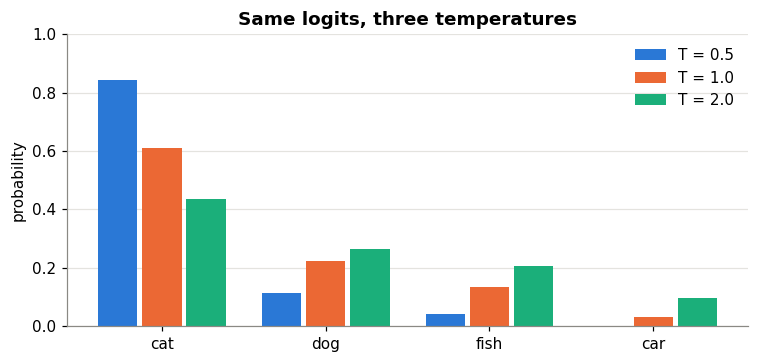

In [4]:
# Figure: how temperature reshapes the same logits
x = np.arange(len(tokens))
width = 0.27
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, (T, color) in enumerate(zip((0.5, 1.0, 2.0), (BLUE, ORANGE, AQUA))):
    ax.bar(x + (i - 1) * width, probs[T], width=width - 0.03, color=color, label=f"T = {T}")
ax.set_xticks(x, tokens)
ax.set_ylabel("probability")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("Same logits, three temperatures")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**What the figure shows:** at $T = 0.5$ "cat" takes 84% of the probability; at $T = 2$ the distribution is much flatter and even "car" gets almost 10%. Low temperature = predictable text, high temperature = more varied (and more error-prone) text.

### Try it yourself

Logits for tokens A, B, C are $[3, 1, 0]$. At $T = 1$, find the probabilities, then the top-p set for $p = 0.9$ and its renormalized probabilities.

<details><summary>Answer</summary>

Minus the max: $[0, -2, -3]$; exponentials $[1, 0.135335, 0.049787]$, sum $1.185122$; probabilities $[0.8438, 0.1142, 0.0420]$. Running total: 0.8438 (below 0.9), then 0.9580 (reached), so keep {A, B}. Renormalized: $[0.8808, 0.1192]$.

</details>

**Common mistake:** top-p keeps the token that **crosses** $p$ (the smallest set whose total is at least $p$), not only the tokens whose running total stays below $p$.

## 3. Perplexity, cross-entropy and bits per token

**What it is:** **cross-entropy (CE)** is the average "surprise" $-\ln p$ of the correct next token: small when the model gave the right token a high probability. **Perplexity (PPL)** $= e^{\text{CE}}$ turns it back into a count: "the model was as unsure as if it were choosing among PPL equally likely tokens".

**Everyday analogy:** a guessing game. A perplexity of 3 means that, on average, you were as unsure as someone picking one of 3 equally likely doors.

**How it works:**

$$\text{CE} = -\frac{1}{N}\sum_{i=1}^{N} \ln p_i \ \ (\text{nats}), \qquad \text{PPL} = e^{\text{CE}}, \qquad \text{bits per token} = \frac{\text{CE}}{\ln 2}, \qquad \text{PPL} = 2^{\text{bits}}$$

### Problem

A model reads a 4-token sentence. The probability it gave to each **correct** next token:

| position | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| $p$(correct token) | 0.5 | 0.25 | 0.8 | 0.1 |

Find the cross-entropy in nats per token, the perplexity, and the bits per token. Then find the loss of a model that guesses uniformly over a 32,000-token vocabulary.

### Solution by hand

1. **Logs:** $\ln 0.5 = -0.693147$, $\ln 0.25 = -1.386294$, $\ln 0.8 = -0.223144$, $\ln 0.1 = -2.302585$.
2. **Sum:** $-4.605170$. (Shortcut: $0.5 \times 0.25 \times 0.8 \times 0.1 = 0.01$ and $\ln 0.01 = -4.605170$.)
3. **Average and flip the sign:** $\text{CE} = 4.605170 / 4 = 1.151293 \approx 1.1513$ nats per token.
4. **Perplexity:** $e^{1.151293} = 3.1623$. (Same as $0.01^{-1/4} = 100^{1/4} = \sqrt{10}$: perplexity is the geometric mean of $1/p$.)
5. **Bits per token:** $1.151293 / 0.693147 = 1.6610$ bits. Check: $2^{1.6610} = 3.1623$.
6. **Uniform guesser:** every token gets $p = 1/V$, so $\text{CE} = \ln V = \ln 32000 = 10.3735$ nats and PPL $= V = 32{,}000$.

**Answer:** CE = 1.1513 nats/token, PPL = 3.1623, 1.6610 bits/token; a uniform guesser has CE = 10.3735.

In [5]:
p_correct = np.array([0.5, 0.25, 0.8, 0.1])
ce_nats = -np.mean(np.log(p_correct))
ppl = np.exp(ce_nats)
bits = ce_nats / np.log(2)

check("sum of ln p", np.log(p_correct).sum(), "-4.605170")
check("cross-entropy (nats per token)", ce_nats, "1.1513")
check("perplexity", ppl, "3.1623")
check("bits per token", bits, "1.6610")
check("perplexity again as 2**bits", 2 ** bits, "3.1623")
check("uniform guesser loss, ln(32000)", np.log(32_000), "10.3735")

OK  sum of ln p                                    code = -4.60517         hand = -4.605170
OK  cross-entropy (nats per token)                 code = 1.15129          hand = 1.1513
OK  perplexity                                     code = 3.16228          hand = 3.1623
OK  bits per token                                 code = 1.66096          hand = 1.6610
OK  perplexity again as 2**bits                    code = 3.16228          hand = 3.1623
OK  uniform guesser loss, ln(32000)                code = 10.3735          hand = 10.3735


### Try it yourself

The correct tokens got probabilities $[0.25, 0.5, 0.5, 0.125]$. Find the bits per token, the perplexity and the cross-entropy in nats. (Hint: use $\log_2$ directly.)

<details><summary>Answer</summary>

$-\log_2 p = [2, 1, 1, 3]$, average $7/4 = 1.75$ bits per token. PPL $= 2^{1.75} = 3.3636$. CE $= 1.75 \times \ln 2 = 1.2130$ nats.

</details>

**Interview tip:** a freshly initialised language model should start with a loss close to $\ln V$ (about 10.37 for $V$ = 32,000). A first loss far above that points to a bug. And never compare perplexities of models with **different tokenizers**: per-token numbers depend on how the text was cut; compare bits per character or per byte instead.

## 4. Transformer parameter count

**What it is:** the number of learned numbers (weights and biases) in the model. "7B" means about 7 billion of them.

**Everyday analogy:** counting the knobs on a mixing desk. Every weight matrix is a grid of knobs: rows × columns.

**How it works:** a layer that maps a vector of size $a$ to size $b$ has $a \times b$ weights plus $b$ biases. For one GPT-2-style decoder block (model width $d$, feed-forward width $d_{ff}$):

| Part | Weights | Biases / other |
|---|---|---|
| Attention: $W_Q, W_K, W_V, W_O$, each $d \times d$ | $4d^2$ | $4d$ |
| Feed-forward (FFN): $d \to d_{ff} \to d$ | $2 \cdot d \cdot d_{ff}$ | $d_{ff} + d$ |
| 2 LayerNorms, each with scale $\gamma$ and shift $\beta$ of size $d$ | | $4d$ |

Outside the blocks: token embeddings $V \cdot d$, learned position embeddings $n_{ctx} \cdot d$, a final LayerNorm $2d$. The output layer **shares** (ties) its weights with the token embeddings, so it adds nothing.

### Problem

| | Config A (small) | Config B (GPT-2-small-like) |
|---|---|---|
| vocabulary $V$ | 10,000 | 50,257 |
| width $d$ | 256 | 768 |
| layers $L$ | 4 | 12 |
| $d_{ff} = 4d$ | 1,024 | 3,072 |
| context $n_{ctx}$ | 512 | 1,024 |

Find the exact total for A, compare its non-embedding part with the rule of thumb $12 \cdot L \cdot d^2$, then do the same for B.

### Solution by hand

**Config A**

1. Token embeddings: $10{,}000 \times 256 = 2{,}560{,}000$.
2. Position embeddings: $512 \times 256 = 131{,}072$.
3. Attention per layer: $4 \times 256^2 = 4 \times 65{,}536 = 262{,}144$ weights $+ 4 \times 256 = 1{,}024$ biases $= 263{,}168$.
4. FFN per layer: $2 \times 256 \times 1{,}024 = 524{,}288$ weights $+ (1{,}024 + 256) = 1{,}280$ biases $= 525{,}568$.
5. LayerNorms per layer: $4 \times 256 = 1{,}024$.
6. One layer: $263{,}168 + 525{,}568 + 1{,}024 = 789{,}760$. Four layers: $4 \times 789{,}760 = 3{,}159{,}040$.
7. Final LayerNorm: $2 \times 256 = 512$.
8. **Total:** $2{,}560{,}000 + 131{,}072 + 3{,}159{,}040 + 512 = 5{,}850{,}624 \approx 5.85$M.
9. **Rule of thumb:** $12 \cdot L \cdot d^2 = 12 \times 4 \times 65{,}536 = 3{,}145{,}728$. Exact non-embedding count: $3{,}159{,}040 + 512 = 3{,}159{,}552$. The rule is off by only $13{,}824 / 3{,}159{,}552 = 0.44\%$. Where the 12 comes from: $4d^2$ (attention) $+ 2 \cdot d \cdot 4d = 8d^2$ (FFN) $= 12d^2$ per layer; biases and norms are tiny.

**Config B (GPT-2-small-like)**

10. Token embeddings: $50{,}257 \times 768 = 38{,}597{,}376$. Positions: $1{,}024 \times 768 = 786{,}432$.
11. Per layer: attention $4 \times 768^2 + 4 \times 768 = 2{,}359{,}296 + 3{,}072 = 2{,}362{,}368$; FFN $2 \times 768 \times 3{,}072 + 3{,}072 + 768 = 4{,}718{,}592 + 3{,}840 = 4{,}722{,}432$; LayerNorms $3{,}072$; total $7{,}087{,}872$.
12. Twelve layers: $12 \times 7{,}087{,}872 = 85{,}054{,}464$. Final LayerNorm: $1{,}536$.
13. **Total:** $38{,}597{,}376 + 786{,}432 + 85{,}054{,}464 + 1{,}536 = 124{,}439{,}808 \approx 124$M, the size usually quoted for GPT-2 small. Rule of thumb: $12 \times 12 \times 768^2 = 84{,}934{,}656 \approx 85$M plus about 39.4M for embeddings gives about 124M, so the shortcut works.
14. **Embedding share:** $(38{,}597{,}376 + 786{,}432) / 124{,}439{,}808 = 31.6\%$. In small models embeddings are a big share; in models with billions of parameters they are only a few percent.

In [6]:
def gpt_params(V, d, L, d_ff, n_ctx):
    """GPT-2-style decoder: learned positions, biases, 2 LayerNorms per block, tied output layer."""
    p = {"token embeddings": V * d,
         "position embeddings": n_ctx * d,
         "attention per layer": 4 * d * d + 4 * d,
         "FFN per layer": 2 * d * d_ff + d_ff + d,
         "LayerNorms per layer": 2 * 2 * d}
    p["one layer"] = p["attention per layer"] + p["FFN per layer"] + p["LayerNorms per layer"]
    p["all layers"] = L * p["one layer"]
    p["final LayerNorm"] = 2 * d
    p["total"] = p["token embeddings"] + p["position embeddings"] + p["all layers"] + p["final LayerNorm"]
    return p

A = gpt_params(V=10_000, d=256, L=4, d_ff=1024, n_ctx=512)
for name, hand in [("token embeddings", "2,560,000"), ("position embeddings", "131,072"),
                   ("attention per layer", "263,168"), ("FFN per layer", "525,568"),
                   ("LayerNorms per layer", "1,024"), ("one layer", "789,760"),
                   ("all layers", "3,159,040"), ("total", "5,850,624")]:
    check(f"A: {name}", A[name], hand)
rule_A = 12 * 4 * 256 ** 2
non_emb_A = A["all layers"] + A["final LayerNorm"]
check("A: 12*L*d^2", rule_A, "3,145,728")
check("A: exact non-embedding", non_emb_A, "3,159,552")
check("A: rule-of-thumb error (%)", 100 * (non_emb_A - rule_A) / non_emb_A, "0.44")

B = gpt_params(V=50_257, d=768, L=12, d_ff=3072, n_ctx=1024)
for name, hand in [("token embeddings", "38,597,376"), ("position embeddings", "786,432"),
                   ("attention per layer", "2,362,368"), ("FFN per layer", "4,722,432"),
                   ("one layer", "7,087,872"), ("all layers", "85,054,464"), ("total", "124,439,808")]:
    check(f"B: {name}", B[name], hand)
check("B: 12*L*d^2", 12 * 12 * 768 ** 2, "84,934,656")
check("B: embedding share (%)", 100 * (B["token embeddings"] + B["position embeddings"]) / B["total"], "31.6")

# Optional cross-check against the Hugging Face GPT-2 implementation (random weights, no download)
try:
    import torch  # noqa: F401
    from transformers import GPT2Config, GPT2Model
    hf = GPT2Model(GPT2Config(vocab_size=50_257, n_positions=1024, n_embd=768, n_layer=12, n_head=12))
    n_hf = sum(t.numel() for t in hf.parameters())
    print(f"transformers GPT2Model: {n_hf:,} parameters")
    assert n_hf == B["total"]
except ImportError:
    print("skipped: needs torch and transformers")

OK  A: token embeddings                            code = 2,560,000        hand = 2,560,000
OK  A: position embeddings                         code = 131,072          hand = 131,072
OK  A: attention per layer                         code = 263,168          hand = 263,168
OK  A: FFN per layer                               code = 525,568          hand = 525,568
OK  A: LayerNorms per layer                        code = 1,024            hand = 1,024
OK  A: one layer                                   code = 789,760          hand = 789,760
OK  A: all layers                                  code = 3,159,040        hand = 3,159,040
OK  A: total                                       code = 5,850,624        hand = 5,850,624
OK  A: 12*L*d^2                                    code = 3,145,728        hand = 3,145,728
OK  A: exact non-embedding                         code = 3,159,552        hand = 3,159,552
OK  A: rule-of-thumb error (%)                     code = 0.43753          hand = 0.44
OK  B

### Try it yourself

Estimate the size of a model with $d$ = 1,024, $L$ = 24, $V$ = 50,000 and $d_{ff} = 4d$, using $12 \cdot L \cdot d^2 + V \cdot d$ (ignore biases, LayerNorms and position embeddings).

<details><summary>Answer</summary>

$12 \times 24 \times 1{,}024^2 = 288 \times 1{,}048{,}576 = 301{,}989{,}888$; embeddings $50{,}000 \times 1{,}024 = 51{,}200{,}000$; total $\approx 353{,}189{,}888 \approx 353$M.

</details>

**Interview tip:** "Why $12Ld^2$?" Attention has 4 matrices of $d \times d$ ($4d^2$) and the FFN has two matrices of $d \times 4d$ ($8d^2$). Models with gated FFNs (SwiGLU) use 3 matrices with a smaller $d_{ff}$, chosen to keep roughly the same count.

## 5. Self-attention compute and memory

**What it is:** in self-attention every token compares itself with every other token, so each head builds an $n \times n$ table of scores ($n$ = number of tokens).

**Everyday analogy:** a meeting where everyone greets everyone. With 10 people there are $10 \times 10 = 100$ greetings (counting each direction); with 20 people there are 400. **Twice the people, four times the greetings.**

**How it works:** $S = QK^\top / \sqrt{d_{head}}$ has $n \times n$ entries per head. After softmax, the output is $A \cdot V$. A matrix product of an $(n \times m)$ by an $(m \times p)$ matrix costs about $2 \cdot n \cdot m \cdot p$ FLOPs (one multiply and one add per term).

### Problem

One attention layer, batch 1, fp16 (2 bytes per number); the full score matrix is stored (no FlashAttention).

| $n$ (tokens) | $d_{model}$ | heads $h$ | $d_{head} = d / h$ |
|---|---|---|---|
| 2,048 | 1,024 | 16 | 64 |

Find: (a) the entries and bytes of one head's score matrix; (b) all 16 heads; (c) the FLOPs of $QK^\top$ and $A \cdot V$ for all heads, compared with the four projections $Q, K, V, O$ ($8 \cdot n \cdot d^2$); (d) what changes when $n$ doubles to 4,096.

### Solution by hand

1. **One head:** $n^2 = 2{,}048^2 = 4{,}194{,}304$ entries; $\times 2$ bytes $= 8{,}388{,}608$ bytes $\approx 8.39$ MB.
2. **All heads:** $16 \times 8{,}388{,}608 = 134{,}217{,}728$ bytes $\approx 134.2$ MB, for **one** layer and **one** sequence.
3. **$QK^\top$ FLOPs:** per head $2 \cdot n \cdot d_{head} \cdot n$; over 16 heads $2 \cdot n^2 \cdot d = 2 \times 4{,}194{,}304 \times 1{,}024 = 8{,}589{,}934{,}592 \approx 8.59$ GFLOPs. $A \cdot V$ costs the same, so attention mixing costs $4 \cdot n^2 \cdot d = 17{,}179{,}869{,}184 \approx 17.18$ GFLOPs.
4. **Projections:** four $d \times d$ matrices applied to $n$ tokens: $4 \times 2 \cdot n \cdot d^2 = 8 \cdot n \cdot d^2 = 8 \times 2{,}048 \times 1{,}048{,}576 = 17{,}179{,}869{,}184 \approx 17.18$ GFLOPs. Equal here because $4n^2d = 8nd^2$ exactly when $n = 2d$. For longer contexts the $n^2$ part wins.
5. **Double the context to $n$ = 4,096:**
   - score memory $\times 4$: $134{,}217{,}728 \times 4 = 536{,}870{,}912$ bytes $\approx 536.9$ MB per layer
   - attention mixing FLOPs $\times 4$: $68.72$ GFLOPs
   - projection FLOPs only $\times 2$: $34.36$ GFLOPs

In [7]:
n, d, h = 2048, 1024, 16
bytes_fp16 = 2
one_head_entries = n * n
check("entries in one head's score matrix", one_head_entries, "4,194,304")
check("bytes, one head", one_head_entries * bytes_fp16, "8,388,608")
check("MB, one head", one_head_entries * bytes_fp16 / 1e6, "8.39")
check("bytes, all heads", h * one_head_entries * bytes_fp16, "134,217,728")
check("MB, all heads", h * one_head_entries * bytes_fp16 / 1e6, "134.2")
check("QK^T FLOPs", 2 * n * n * d, "8,589,934,592")
check("QK^T GFLOPs", 2 * n * n * d / 1e9, "8.59")
check("attention mixing FLOPs (QK^T + AV)", 4 * n * n * d, "17,179,869,184")
check("attention mixing GFLOPs", 4 * n * n * d / 1e9, "17.18")
check("projection FLOPs 8*n*d^2", 8 * n * d * d, "17,179,869,184")

n2 = 2 * n
check("bytes, all heads, n=4096", h * n2 * n2 * bytes_fp16, "536,870,912")
check("MB, all heads, n=4096", h * n2 * n2 * bytes_fp16 / 1e6, "536.9")
check("attention mixing GFLOPs, n=4096", 4 * n2 * n2 * d / 1e9, "68.72")
check("projection GFLOPs, n=4096", 8 * n2 * d * d / 1e9, "34.36")

OK  entries in one head's score matrix             code = 4,194,304        hand = 4,194,304
OK  bytes, one head                                code = 8,388,608        hand = 8,388,608
OK  MB, one head                                   code = 8.38861          hand = 8.39
OK  bytes, all heads                               code = 134,217,728      hand = 134,217,728
OK  MB, all heads                                  code = 134.218          hand = 134.2
OK  QK^T FLOPs                                     code = 8,589,934,592    hand = 8,589,934,592
OK  QK^T GFLOPs                                    code = 8.58993          hand = 8.59
OK  attention mixing FLOPs (QK^T + AV)             code = 17,179,869,184   hand = 17,179,869,184
OK  attention mixing GFLOPs                        code = 17.1799          hand = 17.18
OK  projection FLOPs 8*n*d^2                       code = 17,179,869,184   hand = 17,179,869,184
OK  bytes, all heads, n=4096                       code = 536,870,912      hand = 

### Try it yourself

The context grows from 1,000 to 8,000 tokens. By what factor does one head's score matrix grow? How many bytes does one head need at $n$ = 8,000 in fp16?

<details><summary>Answer</summary>

$(8000 / 1000)^2 = 64$ times larger. $8{,}000^2 \times 2 = 128{,}000{,}000$ bytes $= 128$ MB for one head.

</details>

**Interview tip:** FlashAttention computes exactly the same result in small tiles and never stores the full $n \times n$ matrix, so attention **memory** grows only linearly with $n$; the **FLOPs** are still quadratic.

## 6. Positional encodings: sin/cos and RoPE

**What it is:** attention on its own does not know the order of the tokens ("dog bites man" and "man bites dog" look the same). The original transformer **adds** a sin/cos position vector to each token; **RoPE** (rotary position embedding) instead **rotates** pairs of numbers in the query and key vectors by an angle that grows with the position.

**Everyday analogy:** clock hands. Each position is described by several hands turning at different speeds: the fast hand tells neighbouring positions apart, the slow hands tell far-apart positions apart.

**How it works:**

$$PE(pos, 2i) = \sin\!\Big(\frac{pos}{10000^{2i/d}}\Big), \qquad PE(pos, 2i+1) = \cos\!\Big(\frac{pos}{10000^{2i/d}}\Big)$$

RoPE rotates each pair $(x_1, x_2)$ at position $m$ by the angle $m\theta$:

$$x_1' = x_1\cos(m\theta) - x_2\sin(m\theta), \qquad x_2' = x_1\sin(m\theta) + x_2\cos(m\theta)$$

### Problem

(a) The sinusoidal vector for $pos = 2$ and $d = 4$ (angles in radians). (b) RoPE: rotate the pair $(1.0, 0.5)$ at position $m = 3$ with $\theta = 0.1$ rad (a hypothetical frequency), and check that its length does not change. (c) For $q = (1, 0)$ and $k = (1, 0)$, compare the RoPE score $q' \cdot k'$ for positions (3, 1) and (8, 6).

### Solution by hand

1. **Pair $i = 0$ (dims 0, 1):** divisor $10000^{0} = 1$, angle $2 / 1 = 2$ rad: $\sin 2 = 0.909297$, $\cos 2 = -0.416147$.
2. **Pair $i = 1$ (dims 2, 3):** divisor $10000^{2/4} = 100$, angle $2 / 100 = 0.02$ rad: $\sin 0.02 = 0.019999$, $\cos 0.02 = 0.999800$.
3. **So** $PE(2) = [0.9093, -0.4161, 0.0200, 0.9998]$. The first pair changes quickly with position, the second very slowly.
4. **RoPE angle:** $m\theta = 3 \times 0.1 = 0.3$ rad; $\cos 0.3 = 0.955336$, $\sin 0.3 = 0.295520$.
   - $x_1' = 1.0 \times 0.955336 - 0.5 \times 0.295520 = 0.955336 - 0.147760 = 0.807576$
   - $x_2' = 1.0 \times 0.295520 + 0.5 \times 0.955336 = 0.295520 + 0.477668 = 0.773188$
5. **Length check:** before, $1.0^2 + 0.5^2 = 1.25$; after, $0.807576^2 + 0.773188^2 = 0.652180 + 0.597820 = 1.250000$. A rotation never changes length ($\sqrt{1.25} = 1.118034$).
6. **Relative positions:** for unit vectors, $q' \cdot k' = \cos(\text{angle}_q - \text{angle}_k)$.
   - positions (3, 1): $\cos(0.3 - 0.1) = \cos 0.2 = 0.980067$
   - positions (8, 6): $\cos(0.8 - 0.6) = \cos 0.2 = 0.980067$

   Same score: with RoPE the attention score depends only on the **distance** $m - n$, not on the absolute positions.

In [8]:
def sinusoidal_pe(pos, d):
    pe = np.zeros(d)
    for i in range(d // 2):
        angle = pos / 10000 ** (2 * i / d)
        pe[2 * i], pe[2 * i + 1] = np.sin(angle), np.cos(angle)
    return pe

def rope_rotate(pair, m, theta):
    c, s = np.cos(m * theta), np.sin(m * theta)
    x1, x2 = pair
    return np.array([x1 * c - x2 * s, x1 * s + x2 * c])

pe = sinusoidal_pe(2, 4)
for j, h in enumerate(["0.9093", "-0.4161", "0.0200", "0.9998"]):
    check(f"PE(2)[{j}]", pe[j], h)

r = rope_rotate((1.0, 0.5), m=3, theta=0.1)
check("RoPE x1'", r[0], "0.807576")
check("RoPE x2'", r[1], "0.773188")
check("x1'^2", r[0] ** 2, "0.652180")
check("x2'^2", r[1] ** 2, "0.597820")
check("length before", np.hypot(1.0, 0.5), "1.118034")
check("length after", np.linalg.norm(r), "1.118034")

q = k = (1.0, 0.0)
check("score, positions (3, 1)", rope_rotate(q, 3, 0.1) @ rope_rotate(k, 1, 0.1), "0.980067")
check("score, positions (8, 6)", rope_rotate(q, 8, 0.1) @ rope_rotate(k, 6, 0.1), "0.980067")

OK  PE(2)[0]                                       code = 0.909297         hand = 0.9093
OK  PE(2)[1]                                       code = -0.416147        hand = -0.4161
OK  PE(2)[2]                                       code = 0.0199987        hand = 0.0200
OK  PE(2)[3]                                       code = 0.9998           hand = 0.9998
OK  RoPE x1'                                       code = 0.807576         hand = 0.807576
OK  RoPE x2'                                       code = 0.773188         hand = 0.773188
OK  x1'^2                                          code = 0.65218          hand = 0.652180
OK  x2'^2                                          code = 0.59782          hand = 0.597820
OK  length before                                  code = 1.11803          hand = 1.118034
OK  length after                                   code = 1.11803          hand = 1.118034
OK  score, positions (3, 1)                        code = 0.980067         hand = 0.980067
OK  sc

### Try it yourself

Rotate the pair $(2, 0)$ with RoPE at position $m = 5$, $\theta = 0.1$.

<details><summary>Answer</summary>

Angle $= 0.5$ rad. $x_1' = 2\cos 0.5 = 1.7552$, $x_2' = 2\sin 0.5 = 0.9589$. The length is still 2.

</details>

**Interview tip:** RoPE is applied to the **queries and keys only** (not the values), and each pair $i$ has its own frequency $\theta_i = \text{base}^{-2i/d}$ (base often 10,000). Many "context extension" tricks work by changing this base or rescaling positions.

## 7. Training compute: 6ND, petaFLOP/s-days and Chinchilla

**What it is:** the total number of floating-point operations needed to train a model with $N$ parameters on $D$ tokens.

**Everyday analogy:** painting a house. Total work = wall area × coats; time = total work ÷ (speed per painter × number of painters). Painters never work at their top speed all day, and neither do GPUs.

**How it works:**
- $C \approx 6 \cdot N \cdot D$ FLOPs: about $2ND$ for the forward pass and $4ND$ for the backward pass (it ignores the smaller attention $n^2$ term).
- Achieved speed = peak FLOP/s × **MFU** (model FLOPs utilisation, the fraction of peak you really get).
- 1 **petaFLOP/s-day** = $10^{15}$ FLOP/s for one day $= 10^{15} \times 86{,}400 = 8.64 \times 10^{19}$ FLOPs.
- **Chinchilla rule of thumb:** for the best loss at a fixed training budget, use about $D \approx 20N$ tokens (approximate).
- **Inference:** about $2N$ FLOPs per generated token.

### Problem

| Item | Value |
|---|---|
| parameters $N$ | $7 \times 10^9$ |
| training tokens $D$ | $140 \times 10^9$ |
| GPU peak (hypothetical) | 1,000 TFLOP/s $= 10^{15}$ FLOP/s in bf16 |
| MFU (assumed) | 40% |
| GPUs | 64, assume perfect scaling |
| GPU rental (hypothetical) | \$2.00 per GPU-hour |

Find: (a) $C$; (b) $C$ in petaFLOP/s-days; (c) GPU-hours, GPU-days and wall-clock days on 64 GPUs; (d) the cost; (e) is $D$ compute-optimal? (f) for a budget of $1.2 \times 10^{22}$ FLOPs, what $N$ and $D$ does the 20-tokens-per-parameter rule suggest? (g) inference FLOPs per token for the 7B model.

### Solution by hand

1. **Compute:** $C = 6 \times (7 \times 10^9) \times (1.4 \times 10^{11}) = 58.8 \times 10^{20} = 5.88 \times 10^{21}$ FLOPs.
2. **petaFLOP/s-days:** $5.88 \times 10^{21} / 8.64 \times 10^{19} = 68.06$.
3. **Achieved speed per GPU:** $0.40 \times 10^{15} = 4 \times 10^{14}$ FLOP/s.
4. **GPU time:** $5.88 \times 10^{21} / 4 \times 10^{14} = 1.47 \times 10^{7}$ GPU-seconds; $\div 3{,}600 = 4{,}083.3$ GPU-hours; $\div 24 = 170.14$ GPU-days.
5. **Wall clock on 64 GPUs:** $170.14 / 64 = 2.66$ days ($4{,}083.3 / 64 = 63.8$ hours).
6. **Cost:** $4{,}083.3 \times \$2.00 = \$8{,}166.67$.
7. **Compute-optimal?** $D / N = 140 / 7 = 20$ tokens per parameter: yes, exactly the Chinchilla ratio.
8. **Best split of a budget:** put $D = 20N$ into $C = 6ND$: $C = 120N^2$, so $N = \sqrt{C / 120} = \sqrt{1.2 \times 10^{22} / 120} = \sqrt{10^{20}} = 10^{10}$ = **10B parameters** and $D = 20 \times 10^{10}$ = **200B tokens**. That budget is $1.2 \times 10^{22} / 8.64 \times 10^{19} = 138.89$ petaFLOP/s-days.
9. **Inference:** $2N = 2 \times 7 \times 10^9 = 14$ GFLOPs per generated token.

**Note:** many recent models are trained on far more than 20 tokens per parameter on purpose: a smaller model trained longer costs more to train but is cheaper to serve. The 20× rule answers a narrower question: the best loss for a fixed training budget.

In [9]:
N, D = 7e9, 140e9
C = 6 * N * D
PFS_DAY = 1e15 * 86_400                        # FLOPs in one petaFLOP/s-day
peak, mfu, n_gpus, usd_per_gpu_hour = 1e15, 0.40, 64, 2.00     # hypothetical GPU and price
gpu_seconds = C / (peak * mfu)
gpu_hours = gpu_seconds / 3600

check("training FLOPs C", C, "5.88e21")
check("petaFLOP/s-days", C / PFS_DAY, "68.06")
check("GPU-seconds", gpu_seconds, "1.47e7")
check("GPU-hours", gpu_hours, "4,083.3")
check("GPU-days", gpu_hours / 24, "170.14")
check("wall-clock days on 64 GPUs", gpu_hours / 24 / n_gpus, "2.66")
check("wall-clock hours on 64 GPUs", gpu_hours / n_gpus, "63.8")
check("cost ($)", gpu_hours * usd_per_gpu_hour, "8,166.67")
check("tokens per parameter", D / N, "20")

C_budget = 1.2e22
N_opt = math.sqrt(C_budget / 120)
check("Chinchilla N (billions)", N_opt / 1e9, "10")
check("Chinchilla D (billions of tokens)", 20 * N_opt / 1e9, "200")
check("budget in petaFLOP/s-days", C_budget / PFS_DAY, "138.89")
check("inference GFLOPs per token (2N)", 2 * N / 1e9, "14")

OK  training FLOPs C                               code = 5.88e+21         hand = 5.88e21
OK  petaFLOP/s-days                                code = 68.0556          hand = 68.06
OK  GPU-seconds                                    code = 14,700,000       hand = 1.47e7
OK  GPU-hours                                      code = 4083.33          hand = 4,083.3
OK  GPU-days                                       code = 170.139          hand = 170.14
OK  wall-clock days on 64 GPUs                     code = 2.65842          hand = 2.66
OK  wall-clock hours on 64 GPUs                    code = 63.8021          hand = 63.8
OK  cost ($)                                       code = 8166.67          hand = 8,166.67
OK  tokens per parameter                           code = 20               hand = 20
OK  Chinchilla N (billions)                        code = 10               hand = 10
OK  Chinchilla D (billions of tokens)              code = 200              hand = 200
OK  budget in petaFLOP/s-days    

### Try it yourself

A $3 \times 10^9$-parameter model is trained on Chinchilla-optimal data. Achieved speed is 300 TFLOP/s per GPU and you have 8 GPUs. Find $D$, $C$, the petaFLOP/s-days, the GPU-hours and the wall-clock days.

<details><summary>Answer</summary>

$D = 20 \times 3 \times 10^9 = 60 \times 10^9$ tokens. $C = 6 \times 3 \times 10^9 \times 6 \times 10^{10} = 1.08 \times 10^{21}$ FLOPs $= 12.5$ petaFLOP/s-days. GPU-seconds $= 1.08 \times 10^{21} / 3 \times 10^{14} = 3.6 \times 10^6$ s $= 1{,}000$ GPU-hours. On 8 GPUs: 125 hours $\approx 5.21$ days.

</details>

**Common mistake:** dividing by the GPU's **peak** FLOP/s. Real training reaches only a fraction of it (that fraction is the MFU), so always state the MFU you assume.

## 8. Memory for weights (inference) and for training

**What it is:** memory = number of stored values × bytes per value. For inference you mostly store the **weights**; for training you also store **gradients** and the **optimizer's state**.

**Everyday analogy:** packing a suitcase. The same clothes (parameters) take less room when folded tighter (fewer bits per number), but folding too tight creases them (quantization error, Section 10).

**How it works:** bytes per parameter: fp32 = 4, fp16 = 2, bf16 = 2, int8 = 1, int4 = 0.5. For full training with the Adam optimizer in **mixed precision**, the usual assumption is:

| What is stored | Precision | Bytes per parameter |
|---|---|---|
| weights used in forward/backward | bf16 | 2 |
| gradients | bf16 | 2 |
| master copy of the weights | fp32 | 4 |
| Adam first moment $m$ | fp32 | 4 |
| Adam second moment $v$ | fp32 | 4 |
| **total** | | **16** |

(Pure fp32 training also gives $4 + 4 + 4 + 4 = 16$.) **Activations** (values saved for the backward pass) come on top and depend on batch size, sequence length and checkpointing.

### Problem

A hypothetical model with $N = 7 \times 10^9$ parameters.

Find: (a) the weight memory at fp32, fp16, bf16, int8 and int4; (b) int4 when every group of 64 weights also stores one fp16 scale; (c) the fp16 weights in GiB; (d) full fine-tuning memory with Adam (16 bytes per parameter) plus an **assumed** 20 GB of activations; (e) the minimum number of 80 GB GPUs if that memory could be split perfectly (for example with ZeRO-3 / FSDP sharding).

### Solution by hand

1. **fp32:** $7 \times 10^9 \times 4 = 28 \times 10^9$ bytes $= 28$ GB.
2. **fp16 or bf16:** $\times 2$ bytes $= 14$ GB. (Both use 16 bits; bf16 keeps fp32's range with less precision.)
3. **int8:** $\times 1 = 7$ GB. **int4:** $\times 0.5 = 3.5$ GB.
4. **int4 with scales:** one 16-bit scale per 64 weights adds $16 / 64 = 0.25$ bits per weight, so 4.25 bits $= 0.53125$ bytes; $7 \times 10^9 \times 4.25 / 8 = 3.71875 \times 10^9$ bytes $\approx 3.72$ GB.
5. **GiB:** $14 \times 10^9 / 2^{30} = 14 \times 10^9 / 1{,}073{,}741{,}824 = 13.04$ GiB.
6. **Training:** $7 \times 10^9 \times 16 = 112 \times 10^9$ bytes $= 112$ GB, plus 20 GB of activations $= 132$ GB.
7. **GPUs:** $132 / 80 = 1.65$, so **at least 2** GPUs (in practice more, for buffers and memory fragmentation).

Training needs $16 / 2 = 8$ times the memory of the fp16 weights. Inference also needs the **KV cache** and runtime buffers on top of the weights (Section 9).

In [10]:
N = 7e9
bytes_per_param = {"fp32": 4, "fp16": 2, "bf16": 2, "int8": 1, "int4": 0.5}
for fmt, hand in [("fp32", "28"), ("fp16", "14"), ("bf16", "14"), ("int8", "7"), ("int4", "3.5")]:
    check(f"weights in {fmt} (GB)", N * bytes_per_param[fmt] / GB, hand)
check("int4 + one fp16 scale per 64 weights (GB)", N * (4 + 16 / 64) / 8 / GB, "3.72")
check("fp16 weights in GiB", N * 2 / 2 ** 30, "13.04")

adam_mixed = 2 + 2 + 4 + 4 + 4       # bf16 weights + bf16 grads + fp32 master + Adam m + Adam v
assert adam_mixed == 16 and 4 + 4 + 4 + 4 == 16
train_gb = N * adam_mixed / GB
check("training states (GB)", train_gb, "112")
check("plus 20 GB activations (GB)", train_gb + 20, "132")
check("80 GB GPUs needed (fraction)", (train_gb + 20) / 80, "1.65")
check("80 GB GPUs needed (whole)", math.ceil((train_gb + 20) / 80), "2")

OK  weights in fp32 (GB)                           code = 28               hand = 28
OK  weights in fp16 (GB)                           code = 14               hand = 14
OK  weights in bf16 (GB)                           code = 14               hand = 14
OK  weights in int8 (GB)                           code = 7                hand = 7
OK  weights in int4 (GB)                           code = 3.5              hand = 3.5
OK  int4 + one fp16 scale per 64 weights (GB)      code = 3.71875          hand = 3.72
OK  fp16 weights in GiB                            code = 13.0385          hand = 13.04
OK  training states (GB)                           code = 112              hand = 112
OK  plus 20 GB activations (GB)                    code = 132              hand = 132
OK  80 GB GPUs needed (fraction)                   code = 1.65             hand = 1.65
OK  80 GB GPUs needed (whole)                      code = 2                hand = 2


### Try it yourself

A hypothetical 13B-parameter model: find the fp16 weights, the int4 weights (no scales) and the Adam mixed-precision training memory without activations.

<details><summary>Answer</summary>

fp16: $13 \times 10^9 \times 2 = 26$ GB. int4: $13 \times 10^9 \times 0.5 = 6.5$ GB. Training: $13 \times 10^9 \times 16 = 208$ GB.

</details>

**Interview tip:** memorise "2 bytes per parameter in fp16": a 7B model needs about 14 GB just for its weights, and full fine-tuning with Adam needs about 8 times that before activations.

## 9. KV cache memory: MHA, GQA and MQA

**What it is:** while generating, the model keeps the **keys and values** of all previous tokens in every layer, so it does not recompute them for each new token. This store is the **KV cache**.

**Everyday analogy:** notes taken during a long meeting. They save you from replaying the whole recording each time someone speaks, but the notebook gets thicker with every minute and with every extra meeting you attend at once (batch).

**How it works:**

$$\text{KV bytes} = 2 \times L \times n_{kv} \times d_{head} \times \text{tokens} \times \text{batch} \times \text{bytes per value}$$

The 2 is for K **and** V. In **multi-head attention (MHA)** every query head has its own K/V head ($n_{kv} = n_{heads}$). In **grouped-query attention (GQA)** groups of query heads share one K/V head ($n_{kv} < n_{heads}$). In **multi-query attention (MQA)** all heads share one ($n_{kv} = 1$).

### Problem

A hypothetical model: $L = 32$ layers, 32 query heads, $d_{head} = 128$ ($d_{model}$ = 4,096), KV cache in fp16 (2 bytes), sequences of 4,096 tokens. Weights: 14 GB in fp16 (Section 8). GPU: 80 GB, of which 6 GB is reserved for activations and runtime buffers.

Find: (a) KV cache bytes per token and per sequence for MHA (32 KV heads), GQA (8 KV heads) and MQA (1 KV head); (b) the largest batch of 4,096-token sequences that fits for each.

### Solution by hand

1. **Per token, MHA:** $2 \times 32 \times 32 \times 128 \times 2 = 524{,}288$ bytes $\approx 0.52$ MB for every token in the context.
2. **Per sequence, MHA:** $524{,}288 \times 4{,}096 = 2{,}147{,}483{,}648$ bytes $\approx 2.15$ GB.
3. **GQA (8 KV heads):** $32 / 8 = 4$ times smaller: $131{,}072$ bytes per token, $536{,}870{,}912$ bytes $\approx 0.54$ GB per sequence.
4. **MQA (1 KV head):** 32 times smaller than MHA: $16{,}384$ bytes per token, $67{,}108{,}864$ bytes $\approx 0.067$ GB per sequence.
5. **Memory left for the cache:** $80 - 14 - 6 = 60$ GB $= 60 \times 10^9$ bytes.
6. **Largest batch** (round **down**, a half sequence does not fit):
   - MHA: $60 \times 10^9 / 2{,}147{,}483{,}648 = 27.94$, so **27** sequences
   - GQA: $60 \times 10^9 / 536{,}870{,}912 = 111.76$, so **111** sequences
   - MQA: $60 \times 10^9 / 67{,}108{,}864 = 894.07$, so **894** sequences

At a batch of 27 the MHA cache uses $27 \times 2.147 \approx 58$ GB, about 4 times the weights. For long contexts and big batches, **the KV cache, not the weights, fills the GPU**.

In [11]:
def kv_cache_bytes(layers, kv_heads, head_dim, seq_len, batch, bytes_per_value):
    return 2 * layers * kv_heads * head_dim * seq_len * batch * bytes_per_value

free_bytes = (80 - 14 - 6) * GB
hand = {"MHA": (32, "524,288", "2,147,483,648", "2.15", "27.94", "27"),
        "GQA": (8, "131,072", "536,870,912", "0.54", "111.76", "111"),
        "MQA": (1, "16,384", "67,108,864", "0.067", "894.07", "894")}
for name, (kvh, h_tok, h_seq, h_gb, h_ratio, h_batch) in hand.items():
    per_token = kv_cache_bytes(32, kvh, 128, 1, 1, 2)
    per_seq = kv_cache_bytes(32, kvh, 128, 4096, 1, 2)
    check(f"{name}: bytes per token", per_token, h_tok)
    check(f"{name}: bytes per 4,096-token sequence", per_seq, h_seq)
    check(f"{name}: GB per sequence", per_seq / GB, h_gb)
    check(f"{name}: free memory / per sequence", free_bytes / per_seq, h_ratio)
    check(f"{name}: max batch", free_bytes // per_seq, h_batch)
check("MHA cache at batch 27 (GB)", 27 * kv_cache_bytes(32, 32, 128, 4096, 1, 2) / GB, "58")

OK  MHA: bytes per token                           code = 524,288          hand = 524,288
OK  MHA: bytes per 4,096-token sequence            code = 2,147,483,648    hand = 2,147,483,648
OK  MHA: GB per sequence                           code = 2.14748          hand = 2.15
OK  MHA: free memory / per sequence                code = 27.9397          hand = 27.94
OK  MHA: max batch                                 code = 27               hand = 27
OK  GQA: bytes per token                           code = 131,072          hand = 131,072
OK  GQA: bytes per 4,096-token sequence            code = 536,870,912      hand = 536,870,912
OK  GQA: GB per sequence                           code = 0.536871         hand = 0.54
OK  GQA: free memory / per sequence                code = 111.759          hand = 111.76
OK  GQA: max batch                                 code = 111              hand = 111
OK  MQA: bytes per token                           code = 16,384           hand = 16,384
OK  MQA: bytes per 

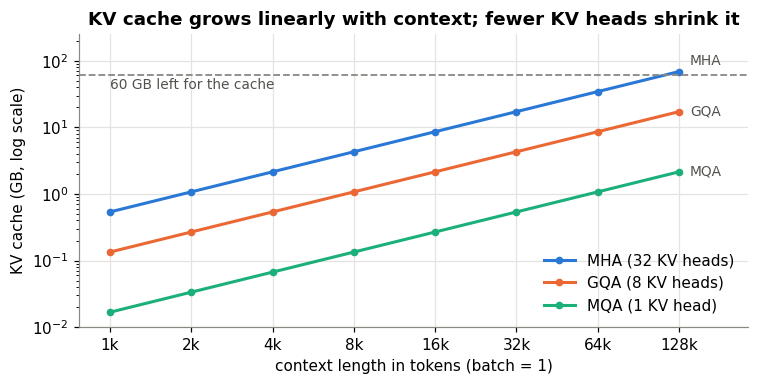

In [12]:
# Figure: KV cache size vs context length (batch 1)
ctx = 2 ** np.arange(10, 18)                         # 1k ... 128k tokens
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, kvh), color in zip([("MHA (32 KV heads)", 32), ("GQA (8 KV heads)", 8), ("MQA (1 KV head)", 1)],
                              (BLUE, ORANGE, AQUA)):
    gb = kv_cache_bytes(32, kvh, 128, ctx, 1, 2) / GB
    ax.plot(ctx, gb, color=color, linewidth=2, marker="o", markersize=4, label=name)
    ax.annotate(name.split(" ")[0], (ctx[-1], gb[-1]), xytext=(7, 7 if kvh == 32 else 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.axhline(60, color=GREY, linestyle="--", linewidth=1.2)
ax.text(ctx[0], 38, "60 GB left for the cache", fontsize=9, color="#52514e")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_ylim(0.01, 250)
ax.set_xticks(ctx, [f"{c // 1024}k" for c in ctx])
ax.set_xlim(ctx[0] / 1.3, ctx[-1] * 1.8)
ax.set_xlabel("context length in tokens (batch = 1)")
ax.set_ylabel("KV cache (GB, log scale)")
ax.set_title("KV cache grows linearly with context; fewer KV heads shrink it")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**What the figure shows:** each doubling of the context doubles the cache (straight lines on log-log axes). With MHA a single 128k-token sequence (68.7 GB) no longer fits in the 60 GB left; GQA needs 4 times less and MQA 32 times less.

### Try it yourself

A model with $L$ = 24 layers, 8 KV heads, $d_{head}$ = 64, fp16 cache, sequences of 8,192 tokens, batch 4. How big is the KV cache?

<details><summary>Answer</summary>

$2 \times 24 \times 8 \times 64 \times 8{,}192 \times 4 \times 2 = 1{,}610{,}612{,}736$ bytes $\approx 1.61$ GB.

</details>

**Common mistake:** using the number of **query** heads instead of **KV** heads for a GQA model (4 times too big in this example), or forgetting the factor 2 for keys and values.

## 10. Quantization: int8, zero-point and int4

**What it is:** storing numbers with fewer bits by mapping them onto a small set of integer **levels**, plus one **scale** (and sometimes a **zero-point**) to map back.

**Everyday analogy:** rounding prices to the nearest 5 cents. Writing them down becomes easier, and each price is off by at most 2.5 cents (half a step).

**How it works:**
- **Symmetric int8:** $s = \max|x| / 127$, $q = \text{round}(x / s)$ clipped to $[-127, 127]$, $\hat x = q \cdot s$. Each error is at most $s/2$.
- **Asymmetric uint8 (affine):** $s = (x_{\max} - x_{\min}) / 255$, zero-point $z = \text{round}(-x_{\min} / s)$, $q = \text{clip}(\text{round}(x/s) + z, 0, 255)$, $\hat x = (q - z) \cdot s$. Good for lopsided data such as activations after ReLU-like functions.
- **Symmetric int4:** $2^4 = 16$ levels; with a symmetric scale we use $[-7, 7]$, $s = \max|x| / 7$.

### Problem

(a) Symmetric int8 for the weights $x = [0.613, -1.337, 0.049, 2.54]$: find $s$, $q$, $\hat x$, the errors and the mean absolute error. (b) Asymmetric uint8 for the activations $a = [-0.5, 0.123, 1.0, 2.05]$. (c) Symmetric int4 for the same weights $x$.

### Solution by hand

**(a) Symmetric int8**
1. $s = 2.54 / 127 = 0.02$.
2. $x / s = [30.65, -66.85, 2.45, 127.0]$, rounded: $q = [31, -67, 2, 127]$.
3. $\hat x = q \times 0.02 = [0.62, -1.34, 0.04, 2.54]$.
4. Errors $x - \hat x = [-0.007, 0.003, 0.009, 0.000]$, all at most $s/2 = 0.01$. Mean absolute error $= (0.007 + 0.003 + 0.009 + 0) / 4 = 0.019 / 4 = 0.00475$.

**(b) Asymmetric uint8**
5. $x_{\min} = -0.5$, $x_{\max} = 2.05$, $s = 2.55 / 255 = 0.01$; $z = \text{round}(0.5 / 0.01) = 50$.
6. $a / s = [-50, 12.3, 100, 205]$; add 50: $[0, 62.3, 150, 255]$; round: $q = [0, 62, 150, 255]$.
7. $\hat a = (q - 50) \times 0.01 = [-0.50, 0.12, 1.00, 2.05]$; the only error is $0.123 - 0.12 = 0.003$.
8. Why bother: a **symmetric** int8 scale for this data would be $2.05 / 127 = 0.016142$, a 61% coarser step, because the levels below $-0.5$ would never be used.

**(c) Symmetric int4**
9. $s = 2.54 / 7 = 0.362857$.
10. $x / s = [1.6894, -3.6846, 0.1350, 7.0]$, rounded: $q = [2, -4, 0, 7]$.
11. $\hat x = [0.725714, -1.451429, 0, 2.54]$; errors $[-0.112714, 0.114429, 0.049, 0]$; mean absolute error $= 0.276143 / 4 = 0.069036 \approx 0.0690$, about 14.5 times the int8 error.

In [13]:
def quantize_symmetric(x, bits=8):
    qmax = 2 ** (bits - 1) - 1                   # 127 for int8, 7 for int4
    scale = np.abs(x).max() / qmax
    q = np.clip(np.round(x / scale), -qmax, qmax).astype(int)
    return q, scale

def quantize_asymmetric(x, bits=8):
    qmax = 2 ** bits - 1                         # 255 for uint8
    scale = (x.max() - x.min()) / qmax
    zero_point = int(round(-x.min() / scale))
    q = np.clip(np.round(x / scale) + zero_point, 0, qmax).astype(int)
    return q, scale, zero_point

x = np.array([0.613, -1.337, 0.049, 2.54])
q8, s8 = quantize_symmetric(x, 8)
x8 = q8 * s8
print("int8 q =", q8.tolist(), " dequantized =", x8.round(6).tolist(), " errors =", (x - x8).round(6).tolist())
assert q8.tolist() == [31, -67, 2, 127]
check("int8 scale", s8, "0.02")
check("int8 max |error|", np.abs(x - x8).max(), "0.009")
check("int8 mean |error|", np.abs(x - x8).mean(), "0.00475")
assert np.abs(x - x8).max() <= s8 / 2 + 1e-12

a = np.array([-0.5, 0.123, 1.0, 2.05])
qa, sa, za = quantize_asymmetric(a)
a_hat = (qa - za) * sa
print("uint8 q =", qa.tolist(), " zero-point =", za, " dequantized =", a_hat.round(6).tolist())
assert qa.tolist() == [0, 62, 150, 255] and za == 50
check("uint8 scale", sa, "0.01")
check("uint8 error on 0.123", a[1] - a_hat[1], "0.003")
check("symmetric int8 scale for the same data", np.abs(a).max() / 127, "0.016142")

q4, s4 = quantize_symmetric(x, 4)
x4 = q4 * s4
print("int4 q =", q4.tolist(), " dequantized =", x4.round(6).tolist(), " errors =", (x - x4).round(6).tolist())
assert q4.tolist() == [2, -4, 0, 7]
check("int4 scale", s4, "0.362857")
check("int4 x/s for 0.613", x[0] / s4, "1.6894")
check("int4 error on 0.613", x[0] - x4[0], "-0.112714")
check("int4 error on -1.337", x[1] - x4[1], "0.114429")
check("int4 mean |error|", np.abs(x - x4).mean(), "0.0690")
check("int4 / int8 error ratio", np.abs(x - x4).mean() / np.abs(x - x8).mean(), "14.5")

int8 q = [31, -67, 2, 127]  dequantized = [0.62, -1.34, 0.04, 2.54]  errors = [-0.007, 0.003, 0.009, 0.0]
OK  int8 scale                                     code = 0.02             hand = 0.02
OK  int8 max |error|                               code = 0.009            hand = 0.009
OK  int8 mean |error|                              code = 0.00475          hand = 0.00475
uint8 q = [0, 62, 150, 255]  zero-point = 50  dequantized = [-0.5, 0.12, 1.0, 2.05]
OK  uint8 scale                                    code = 0.01             hand = 0.01
OK  uint8 error on 0.123                           code = 0.003            hand = 0.003
OK  symmetric int8 scale for the same data         code = 0.0161417        hand = 0.016142
int4 q = [2, -4, 0, 7]  dequantized = [0.725714, -1.451429, 0.0, 2.54]  errors = [-0.112714, 0.114429, 0.049, 0.0]
OK  int4 scale                                     code = 0.362857         hand = 0.362857
OK  int4 x/s for 0.613                             code = 1.68937        

### Try it yourself

Quantize $x = [1.2, -0.35, 0.8]$ with symmetric int8. Find $s$, $q$, $\hat x$ and the errors.

<details><summary>Answer</summary>

$s = 1.2 / 127 = 0.009449$. $x / s = [127, -37.04, 84.67]$, so $q = [127, -37, 85]$. $\hat x = [1.2, -0.349606, 0.803150]$. Errors $x - \hat x = [0, -0.000394, -0.003150]$, all below $s / 2 = 0.004724$.

</details>

**Common mistake:** one **outlier** (a single large $|x|$) makes $s$ large and wipes out the precision of all the small values. That is why LLM quantizers give each small group of weights (per channel, or every 64-128 weights) its own scale.

## 11. Pruning: sparsity, memory and speed

**What it is:** setting some weights to zero (removing them). **Sparsity** = fraction of weights that are zero.
- **Unstructured:** any individual weights, usually the smallest in magnitude.
- **Semi-structured N:M** (for example **2:4**): in every group of 4 consecutive weights at most 2 are non-zero, a pattern some GPUs can exploit.
- **Structured:** remove whole neurons, attention heads or layers, so the matrices really get smaller.

**Everyday analogy:** trimming a hedge. Plucking random single leaves (unstructured) barely changes how long it takes to walk past it; cutting off whole branches (structured) really makes it smaller.

### Problem

(a) Prune $W = \begin{bmatrix} 0.8 & -0.1 & 0.05 & -0.02 \\ 0.3 & 0.7 & 0.9 & 0.15 \end{bmatrix}$ to 50% sparsity, first by **global magnitude**, then with the **2:4** pattern (per group of 4 in each row). Compare the total kept magnitude.

(b) A hypothetical 7B fp16 model pruned to 50% unstructured sparsity. Memory if stored (1) dense; (2) sparse, with a 2-byte value + 2-byte (16-bit) index per non-zero (ignore row pointers); (3) the same with 4-byte (32-bit) indices; (4) at 90% sparsity with 16-bit indices; (5) in a 2:4 format with 2 bytes per kept value + 2 bits of position metadata per kept value.

(c) Structured: remove 25% of the FFN neurons of one layer with $d$ = 4,096 and $d_{ff}$ = 16,384 (ignore biases). Parameters and fp16 memory saved.

### Solution by hand

1. **Global magnitude:** sorted $|w|$: 0.02, 0.05, 0.1, 0.15, 0.3, 0.7, 0.8, 0.9. Keep the 4 largest (0.3, 0.7, 0.8, 0.9): $W_{global} = \begin{bmatrix} 0.8 & 0 & 0 & 0 \\ 0.3 & 0.7 & 0.9 & 0 \end{bmatrix}$. Sparsity $4/8 = 50\%$; kept magnitude $0.8 + 0.3 + 0.7 + 0.9 = 2.7$. Row 1 has 1 non-zero and row 2 has 3, so this is **not** a valid 2:4 pattern.
2. **2:4:** keep the 2 largest in each group of 4: row 1 keeps 0.8 and -0.1, row 2 keeps 0.7 and 0.9: $W_{2:4} = \begin{bmatrix} 0.8 & -0.1 & 0 & 0 \\ 0 & 0.7 & 0.9 & 0 \end{bmatrix}$. Kept magnitude $0.8 + 0.1 + 0.7 + 0.9 = 2.5$, slightly less than 2.7: the price of a hardware-friendly pattern.
3. **Dense storage:** the zeros still take 2 bytes each: $7 \times 10^9 \times 2 = 14$ GB. **No saving.**
4. **Sparse, 16-bit index:** $3.5 \times 10^9$ non-zeros $\times (2 + 2)$ bytes $= 14$ GB. Still no saving at 50%.
5. **Sparse, 32-bit index:** $3.5 \times 10^9 \times (2 + 4) = 21$ GB. **Worse** than dense!
6. **90% sparse, 16-bit index:** $0.7 \times 10^9 \times 4 = 2.8$ GB, an 80% saving.
7. **2:4 format:** values $3.5 \times 10^9 \times 2 = 7$ GB; metadata $3.5 \times 10^9 \times 2$ bits $= 7 \times 10^9$ bits $= 0.875$ GB; total $7.875$ GB (about 44% saved).
8. **Structured FFN pruning:** before, $2 \times 4{,}096 \times 16{,}384 = 134{,}217{,}728$ parameters; after ($d_{ff}$ = 12,288), $2 \times 4{,}096 \times 12{,}288 = 100{,}663{,}296$; saved $33{,}554{,}432$ parameters $\times$ 2 bytes $= 67{,}108{,}864$ bytes $\approx 67.1$ MB per layer. The matrices are simply smaller, so ordinary dense kernels run faster.

**Why unstructured sparsity may not speed things up:** GPU matrix-multiply kernels are built for dense blocks. Scattered zeros are still loaded and multiplied unless a special sparse kernel is used, and sparse kernels pay for index lookups and irregular memory access, so they usually win only at high sparsity. The 2:4 pattern exists because some GPUs have hardware support for it (designed for up to about 2× faster matrix math, less end to end).

In [14]:
W = np.array([[0.8, -0.1, 0.05, -0.02],
              [0.3,  0.7, 0.9,   0.15]])

def prune_global(W, sparsity):
    k_keep = int(round(W.size * (1 - sparsity)))
    keep = np.argsort(np.abs(W).ravel())[-k_keep:]           # indices of the largest |w|
    mask = np.zeros(W.size, dtype=bool)
    mask[keep] = True
    return np.where(mask.reshape(W.shape), W, 0.0)

def prune_n_m(W, n=2, m=4):
    out = np.zeros_like(W)
    for r in range(W.shape[0]):
        for g in range(0, W.shape[1], m):
            block = W[r, g:g + m]
            keep = np.argsort(np.abs(block))[-n:]
            out[r, g + keep] = block[keep]
    return out

Wg, W24 = prune_global(W, 0.5), prune_n_m(W)
print("global 50%:\n", Wg, "\n2:4:\n", W24)
check("global: sparsity (%)", 100 * np.mean(Wg == 0), "50")
check("global: kept magnitude", np.abs(Wg).sum(), "2.7")
check("2:4: kept magnitude", np.abs(W24).sum(), "2.5")
print("non-zeros per row, global:", (Wg != 0).sum(axis=1).tolist(), " 2:4:", (W24 != 0).sum(axis=1).tolist())
assert (Wg != 0).sum(axis=1).tolist() == [1, 3] and (W24 != 0).sum(axis=1).tolist() == [2, 2]

N = 7e9
check("dense storage (GB)", N * 2 / GB, "14")
check("50% sparse, 16-bit index (GB)", 0.5 * N * (2 + 2) / GB, "14")
check("50% sparse, 32-bit index (GB)", 0.5 * N * (2 + 4) / GB, "21")
check("90% sparse, 16-bit index (GB)", 0.1 * N * (2 + 2) / GB, "2.8")
check("2:4 values + metadata (GB)", (0.5 * N * 2 + 0.5 * N * 2 / 8) / GB, "7.875")

before, after = 2 * 4096 * 16384, 2 * 4096 * 12288
check("FFN params before", before, "134,217,728")
check("FFN params after", after, "100,663,296")
check("params saved", before - after, "33,554,432")
check("MB saved (fp16)", (before - after) * 2 / 1e6, "67.1")

global 50%:
 [[0.8 0.  0.  0. ]
 [0.3 0.7 0.9 0. ]] 
2:4:
 [[ 0.8 -0.1  0.   0. ]
 [ 0.   0.7  0.9  0. ]]
OK  global: sparsity (%)                           code = 50               hand = 50
OK  global: kept magnitude                         code = 2.7              hand = 2.7
OK  2:4: kept magnitude                            code = 2.5              hand = 2.5
non-zeros per row, global: [1, 3]  2:4: [2, 2]
OK  dense storage (GB)                             code = 14               hand = 14
OK  50% sparse, 16-bit index (GB)                  code = 14               hand = 14
OK  50% sparse, 32-bit index (GB)                  code = 21               hand = 21
OK  90% sparse, 16-bit index (GB)                  code = 2.8              hand = 2.8
OK  2:4 values + metadata (GB)                     code = 7.875            hand = 7.875
OK  FFN params before                              code = 134,217,728      hand = 134,217,728
OK  FFN params after                               code = 100,663,2

### Try it yourself

A hypothetical 1B-parameter fp16 model is pruned to 75% unstructured sparsity and stored as a 2-byte value + a 2-byte index per non-zero. How much memory does it need compared with dense storage? At what sparsity does this format break even?

<details><summary>Answer</summary>

Non-zeros: $0.25 \times 10^9$, so $0.25 \times 10^9 \times 4 = 1$ GB versus $10^9 \times 2 = 2$ GB dense: 50% saved. Break-even when the non-zero fraction × 4 bytes = 2 bytes, i.e. at 50% sparsity.

</details>

**Interview tip:** "We pruned 50% of the weights but the model is neither smaller nor faster" is a classic: the zeros were stored densely and run through dense kernels. Ask which **format** and which **kernel** will use the sparsity.

## 12. Knowledge distillation: soft labels, KL and the $T^2$ factor

**What it is:** a small **student** model learns to copy the full probability distribution of a big **teacher** model (its **soft labels**), not only the correct answer.

**Everyday analogy:** learning from a teacher who says "it is probably a cat, maybe a dog, certainly not a car" instead of only handing you the answer key. The "maybe a dog" part (sometimes called **dark knowledge**) is extra information.

**How it works:**
- Soften both models with the same temperature $T$: $p^{T} = \text{softmax}(z / T)$.
- $\text{KL}(p_t \,\Vert\, p_s) = \sum_i p_{t,i} \ln \dfrac{p_{t,i}}{p_{s,i}}$; the **soft cross-entropy** is $H(p_t, p_s) = -\sum_i p_{t,i} \ln p_{s,i} = \text{KL} + H(p_t)$ (same gradient for the student, since $H(p_t)$ is fixed).
- Loss $= \alpha \cdot \text{CE}(y, \text{softmax}(z_s)) + (1 - \alpha) \cdot T^2 \cdot \text{KL}(p_t^{T} \,\Vert\, p_s^{T})$.

### Problem

Three classes; the true class is 0. $T = 2$, $\alpha = 0.5$.

| | class 0 | class 1 | class 2 |
|---|---|---|---|
| teacher logits $z_t$ | 4.0 | 2.0 | 1.0 |
| student logits $z_s$ | 3.0 | 2.5 | 0.5 |

Find the soft probabilities of both models, the KL, the soft cross-entropy, $T^2 \cdot$ KL, the hard-label cross-entropy (at $T = 1$) and the total loss.

### Solution by hand

1. **Teacher at $T = 2$:** $z_t / 2 = [2, 1, 0.5]$; minus the max: $[0, -1, -1.5]$; exponentials $[1, 0.367879, 0.223130]$, sum $1.591010$; $p_t = [0.628532, 0.231224, 0.140244]$.
2. **Student at $T = 2$:** $z_s / 2 = [1.5, 1.25, 0.25]$; minus the max: $[0, -0.25, -1.25]$; exponentials $[1, 0.778801, 0.286505]$, sum $2.065306$; $p_s = [0.484190, 0.377087, 0.138723]$.
3. **Log ratios** $\ln(p_t / p_s)$: $\ln 1.298110 = 0.260909$, $\ln 0.613184 = -0.489091$, $\ln 1.010969 = 0.010909$.
4. **KL:** $0.628532 \times 0.260909 + 0.231224 \times (-0.489091) + 0.140244 \times 0.010909 = 0.163990 - 0.113089 + 0.001530 \approx 0.05243$, so **KL = 0.0524**.
5. **Soft cross-entropy:** teacher entropy $H(p_t) = -\sum p_t \ln p_t = 0.9060$, so $H(p_t, p_s) = 0.0524 + 0.9060 = 0.9584$.
6. **Scaled soft loss:** $T^2 \cdot \text{KL} = 4 \times 0.05243 = 0.2097$.
7. **Hard loss ($T = 1$):** student logits minus the max: $[0, -0.5, -2.5]$; exponentials $[1, 0.606531, 0.082085]$, sum $1.688616$; $p_s(\text{class } 0) = 0.592201$; CE $= -\ln 0.592201 = 0.5239$.
8. **Total:** $0.5 \times 0.5239 + 0.5 \times 0.2097 = 0.5 \times 0.7336 = 0.3668$.

**Why $T^2$:** softening with temperature $T$ makes the gradients of the soft term roughly $1/T^2$ smaller, so multiplying by $T^2$ keeps the soft and hard terms balanced when you change $T$ (Hinton, Vinyals and Dean, 2015). The code below shows it numerically.

In [15]:
z_teacher = np.array([4.0, 2.0, 1.0])
z_student = np.array([3.0, 2.5, 0.5])
T, alpha = 2.0, 0.5

p_t, p_s = softmax(z_teacher, T), softmax(z_student, T)
for name, vec, hands in [("teacher", p_t, ["0.628532", "0.231224", "0.140244"]),
                         ("student", p_s, ["0.484190", "0.377087", "0.138723"])]:
    for i, h in enumerate(hands):
        check(f"{name} soft p[{i}] at T=2", vec[i], h)
check("teacher sum of exponentials", np.exp(z_teacher / T - (z_teacher / T).max()).sum(), "1.591010")
check("student sum of exponentials", np.exp(z_student / T - (z_student / T).max()).sum(), "2.065306")

log_ratio = np.log(p_t / p_s)
for i, h in enumerate(["0.260909", "-0.489091", "0.010909"]):
    check(f"ln(p_t/p_s)[{i}]", log_ratio[i], h)
kl = np.sum(p_t * log_ratio)
H_t = -np.sum(p_t * np.log(p_t))
check("KL(teacher || student)", kl, "0.0524")
check("teacher entropy", H_t, "0.9060")
check("soft cross-entropy", -np.sum(p_t * np.log(p_s)), "0.9584")
check("T^2 * KL", T ** 2 * kl, "0.2097")
p_hard = softmax(z_student, 1.0)
hard_ce = -np.log(p_hard[0])
check("student p(class 0) at T=1", p_hard[0], "0.592201")
check("hard cross-entropy", hard_ce, "0.5239")
check("total distillation loss", alpha * hard_ce + (1 - alpha) * T ** 2 * kl, "0.3668")

# Why T^2: the gradient of KL w.r.t. the student logits is (p_s - p_t) / T; it shrinks like 1/T^2
print("\n T   |grad of KL|   T^2 * |grad|")
grads = {}
for T_ in (1, 2, 4, 8):
    g = (softmax(z_student, T_) - softmax(z_teacher, T_)) / T_
    grads[T_] = np.linalg.norm(g)
    print(f"{T_:2d}   {grads[T_]:.6f}       {T_ ** 2 * grads[T_]:.6f}")
assert grads[8] / grads[2] < 0.1                   # raw gradient collapses...
assert 0.9 < (64 * grads[8]) / (4 * grads[2]) < 1.1   # ...the T^2-scaled one stays about the same

OK  teacher soft p[0] at T=2                       code = 0.628532         hand = 0.628532
OK  teacher soft p[1] at T=2                       code = 0.231224         hand = 0.231224
OK  teacher soft p[2] at T=2                       code = 0.140244         hand = 0.140244
OK  student soft p[0] at T=2                       code = 0.48419          hand = 0.484190
OK  student soft p[1] at T=2                       code = 0.377087         hand = 0.377087
OK  student soft p[2] at T=2                       code = 0.138723         hand = 0.138723
OK  teacher sum of exponentials                    code = 1.59101          hand = 1.591010
OK  student sum of exponentials                    code = 2.06531          hand = 2.065306
OK  ln(p_t/p_s)[0]                                 code = 0.260909         hand = 0.260909
OK  ln(p_t/p_s)[1]                                 code = -0.489091        hand = -0.489091
OK  ln(p_t/p_s)[2]                                 code = 0.0109094        hand = 0.01090

### Try it yourself

Teacher soft probabilities $[0.7, 0.2, 0.1]$ and student soft probabilities $[0.5, 0.3, 0.2]$, both already computed at $T = 2$. Find $\text{KL}(p_t \,\Vert\, p_s)$ and $T^2 \cdot \text{KL}$.

<details><summary>Answer</summary>

$0.7 \ln 1.4 + 0.2 \ln(2/3) + 0.1 \ln 0.5 = 0.235531 - 0.081093 - 0.069315 = 0.085123 \approx 0.0851$. Times $T^2 = 4$: $0.3405$.

</details>

**Common mistake:** softening only the teacher. The **same** $T$ must be applied to teacher and student in the soft term; the hard-label term uses $T = 1$.

## 13. PEFT: LoRA, prompt tuning, prefix tuning and QLoRA

**What it is:** **parameter-efficient fine-tuning (PEFT)** adapts a big model by training only a small number of new parameters while the original weights stay frozen.

**Everyday analogy:** instead of rewriting a whole textbook, you add sticky notes. LoRA's notes are small corrections to the weight matrices; prompt tuning's notes are a few learned "words" placed in front of every input.

**How it works:**
- **LoRA:** $W' = W + \frac{\alpha}{r} B A$ with $B$ of size $d \times r$ and $A$ of size $r \times k$. Trainable: $r(d + k)$ instead of $d \cdot k$. $B$ starts at zero, so training starts from the original model.
- **Prompt tuning (soft prompt):** $n_{virtual} \times d_{model}$ trainable numbers (learned embeddings put before the input).
- **Prefix tuning:** a learned key and value prefix in **every** layer: $n_{virtual} \times 2 \times L \times d_{model}$.
- **QLoRA:** LoRA on top of a base model stored in 4 bits.

### Problem

A hypothetical model with $N = 7 \times 10^9$ parameters, $L = 32$ layers, $d = 4{,}096$.

Find: (a) LoRA with $r = 8$ on one $4{,}096 \times 4{,}096$ matrix: trainable vs full, as a %; (b) LoRA on $W_Q$ and $W_V$ in all 32 layers: total and % of 7B, and the same for all four attention matrices; (c) prompt tuning and prefix tuning with 20 virtual tokens; (d) QLoRA memory: base weights in 4 bits plus one 32-bit scale per 64 weights, the LoRA parameters of (b) trained at 16 bytes per parameter (Section 8), activations ignored; compare with 112 GB for full fine-tuning; (e) the LoRA scaling factor for $\alpha = 16$.

### Solution by hand

1. **One matrix:** $r(d + k) = 8 \times (4{,}096 + 4{,}096) = 65{,}536$ vs $d \cdot k = 16{,}777{,}216$; $65{,}536 / 16{,}777{,}216 = 0.390625\%$ (exactly $1/256$).
2. **$W_Q$ and $W_V$, 32 layers:** $32 \times 2 \times 65{,}536 = 4{,}194{,}304 \approx 4.19$M; as a share of 7B: $4{,}194{,}304 / 7 \times 10^9 = 0.0599\%$. All four attention matrices: $8{,}388{,}608$, which is $0.1198\%$.
3. **Prompt tuning:** $20 \times 4{,}096 = 81{,}920$ parameters ($0.00117\%$ of 7B). **Prefix tuning:** $20 \times 2 \times 32 \times 4{,}096 = 5{,}242{,}880$.
4. **QLoRA memory:**
   - base weights at 4 bits: $7 \times 10^9 \times 0.5 = 3.5$ GB; with one 32-bit scale per 64 weights, $32 / 64 = 0.5$ extra bits, so 4.5 bits per weight: $7 \times 10^9 \times 4.5 / 8 = 3.9375$ GB
   - LoRA weights + gradients + Adam states: $4{,}194{,}304 \times 16 = 67{,}108{,}864$ bytes $\approx 0.0671$ GB
   - total $3.9375 + 0.0671 = 4.0046 \approx 4.00$ GB plus activations, versus 112 GB for full fine-tuning: about $112 / 4.0046 = 28$ times less
5. **Scaling:** $\alpha / r = 16 / 8 = 2$: the update $BA$ is multiplied by 2 before it is added to $W$.

In [16]:
d = k = 4096
r = 8
lora_one = r * (d + k)
full_one = d * k
check("LoRA params, one matrix", lora_one, "65,536")
check("full params, one matrix", full_one, "16,777,216")
check("LoRA share of the matrix (%)", 100 * lora_one / full_one, "0.390625")

N, L = 7e9, 32
lora_qv = L * 2 * lora_one
lora_all = L * 4 * lora_one
check("LoRA on W_Q, W_V, 32 layers", lora_qv, "4,194,304")
check("  share of 7B (%)", 100 * lora_qv / N, "0.0599")
check("LoRA on all 4 attention matrices", lora_all, "8,388,608")
check("  share of 7B (%)", 100 * lora_all / N, "0.1198")

n_virtual = 20
check("prompt tuning params", n_virtual * d, "81,920")
check("  share of 7B (%)", 100 * n_virtual * d / N, "0.00117")
check("prefix tuning params", n_virtual * 2 * L * d, "5,242,880")

base_gb = N * 4.5 / 8 / GB                 # 4-bit weights + 0.5 bit of scale overhead
lora_state = lora_qv * 16                  # weights, grads, master copy, Adam m and v
check("4-bit base, no scales (GB)", N * 0.5 / GB, "3.5")
check("4-bit base with scales (GB)", base_gb, "3.9375")
check("LoRA training state (bytes)", lora_state, "67,108,864")
check("QLoRA total (GB)", base_gb + lora_state / GB, "4.00")
check("full fine-tune / QLoRA", 112 / (base_gb + lora_state / GB), "28")
check("LoRA scale alpha/r", 16 / r, "2")

OK  LoRA params, one matrix                        code = 65,536           hand = 65,536
OK  full params, one matrix                        code = 16,777,216       hand = 16,777,216
OK  LoRA share of the matrix (%)                   code = 0.390625         hand = 0.390625
OK  LoRA on W_Q, W_V, 32 layers                    code = 4,194,304        hand = 4,194,304
OK    share of 7B (%)                              code = 0.0599186        hand = 0.0599
OK  LoRA on all 4 attention matrices               code = 8,388,608        hand = 8,388,608
OK    share of 7B (%)                              code = 0.119837         hand = 0.1198
OK  prompt tuning params                           code = 81,920           hand = 81,920
OK    share of 7B (%)                              code = 0.00117029       hand = 0.00117
OK  prefix tuning params                           code = 5,242,880        hand = 5,242,880
OK  4-bit base, no scales (GB)                     code = 3.5              hand = 3.5
OK  4-bi

### Try it yourself

LoRA with $r = 16$ on square matrices with $d = k = 2{,}048$. Find the trainable parameters per matrix, the share of the matrix, and the total for 24 layers × 4 attention matrices.

<details><summary>Answer</summary>

$16 \times (2{,}048 + 2{,}048) = 65{,}536$ vs $2{,}048^2 = 4{,}194{,}304$, so $1.5625\%$. Total: $24 \times 4 \times 65{,}536 = 6{,}291{,}456$.

</details>

**Interview tip:** after training you can **merge** $\frac{\alpha}{r}BA$ into $W$, so LoRA adds **no extra latency** at inference. And LoRA cuts the memory for gradients and optimizer states, not for the frozen weights: that is what the 4-bit base in QLoRA is for.

## 14. Mixture of experts: total vs active parameters

**What it is:** in a **mixture-of-experts (MoE)** layer, the single feed-forward network is replaced by several "expert" FFNs, and a small **router** sends each token to only the top-$k$ of them.

**Everyday analogy:** a hospital with 8 specialists where each patient sees only the 2 most relevant ones. The hospital must employ (store) all 8, but each visit costs only 2 consultations.

**How it works:** **total** parameters (what you must store) include every expert; **active** parameters (what each token uses, so what sets the FLOPs) include only the $k$ chosen experts plus everything that is shared (attention, embeddings, router).

### Problem

A hypothetical MoE model; ignore biases and LayerNorms.

| $d$ | $d_{ff}$ | layers $L$ | experts per layer | routing | vocabulary $V$ |
|---|---|---|---|---|---|
| 2,048 | 8,192 | 24 | 8 | top-2 | 32,000 (tied embeddings) |

Attention per layer: $4d^2$. One expert: $2 \cdot d \cdot d_{ff}$. Router per layer: $d \times 8$.

Find: total and active parameters, their ratio, the fp16 memory, the FLOPs per token (≈ 2 × active) and the size of the same model with a single dense FFN.

### Solution by hand

1. **Attention per layer:** $4 \times 2{,}048^2 = 4 \times 4{,}194{,}304 = 16{,}777{,}216$.
2. **One expert:** $2 \times 2{,}048 \times 8{,}192 = 33{,}554{,}432$; eight experts: $268{,}435{,}456$.
3. **Router:** $2{,}048 \times 8 = 16{,}384$.
4. **Per layer:** total $16{,}777{,}216 + 268{,}435{,}456 + 16{,}384 = 285{,}229{,}056$; active $16{,}777{,}216 + 2 \times 33{,}554{,}432 + 16{,}384 = 83{,}902{,}464$.
5. **24 layers:** total $6{,}845{,}497{,}344$; active $2{,}013{,}659{,}136$.
6. **Embeddings:** $32{,}000 \times 2{,}048 = 65{,}536{,}000$ (shared by every token).
7. **Model:** total $6{,}845{,}497{,}344 + 65{,}536{,}000 = 6{,}911{,}033{,}344 \approx 6.91$B; active $2{,}013{,}659{,}136 + 65{,}536{,}000 = 2{,}079{,}195{,}136 \approx 2.08$B; ratio $6.911 / 2.079 = 3.32$.
8. **Memory (fp16):** $6.911 \times 10^9 \times 2 = 13.82$ GB, because **all** experts must be loaded.
9. **Compute:** $\approx 2 \times 2.079 \times 10^9 = 4.16$ GFLOPs per token, like a 2.08B dense model.
10. **Dense version (one FFN, no router):** $24 \times (16{,}777{,}216 + 33{,}554{,}432) + 65{,}536{,}000 = 1{,}273{,}495{,}552 \approx 1.27$B.

So the MoE stores about 5.4 times as many parameters as the dense version ($6.91 / 1.27$) while each token costs only about 1.6 times as much compute ($2.08 / 1.27$).

In [17]:
d, d_ff, L, E, top_k, V = 2048, 8192, 24, 8, 2, 32_000
attn = 4 * d * d
expert = 2 * d * d_ff
router = d * E
emb = V * d
total_layer = attn + E * expert + router
active_layer = attn + top_k * expert + router
total = L * total_layer + emb
active = L * active_layer + emb
dense = L * (attn + expert) + emb

check("attention per layer", attn, "16,777,216")
check("one expert", expert, "33,554,432")
check("eight experts", E * expert, "268,435,456")
check("router per layer", router, "16,384")
check("total per layer", total_layer, "285,229,056")
check("active per layer", active_layer, "83,902,464")
check("total, 24 layers", L * total_layer, "6,845,497,344")
check("active, 24 layers", L * active_layer, "2,013,659,136")
check("embeddings", emb, "65,536,000")
check("total parameters", total, "6,911,033,344")
check("active parameters", active, "2,079,195,136")
check("total / active", total / active, "3.32")
check("fp16 memory (GB)", total * 2 / GB, "13.82")
check("GFLOPs per token", 2 * active / 1e9, "4.16")
check("dense model with one FFN", dense, "1,273,495,552")
check("MoE stores x dense", total / dense, "5.4")
check("MoE compute x dense", active / dense, "1.6")

OK  attention per layer                            code = 16,777,216       hand = 16,777,216
OK  one expert                                     code = 33,554,432       hand = 33,554,432
OK  eight experts                                  code = 268,435,456      hand = 268,435,456
OK  router per layer                               code = 16,384           hand = 16,384
OK  total per layer                                code = 285,229,056      hand = 285,229,056
OK  active per layer                               code = 83,902,464       hand = 83,902,464
OK  total, 24 layers                               code = 6,845,497,344    hand = 6,845,497,344
OK  active, 24 layers                              code = 2,013,659,136    hand = 2,013,659,136
OK  embeddings                                     code = 65,536,000       hand = 65,536,000
OK  total parameters                               code = 6,911,033,344    hand = 6,911,033,344
OK  active parameters                              code = 2,079

### Try it yourself

Each layer has 50M shared parameters (attention etc.) and 8 experts of 100M each, top-2 routing, 32 layers; ignore embeddings. Find the total and active parameters.

<details><summary>Answer</summary>

Total $= 32 \times (50 + 8 \times 100)$M $= 32 \times 850$M $= 27.2$B. Active $= 32 \times (50 + 2 \times 100)$M $= 32 \times 250$M $= 8.0$B.

</details>

**Interview tip:** MoE saves **compute**, not **memory**: all experts must sit in (GPU or offloaded) memory. A name like "8 × 7B" does not mean $8 \times 7 = 56$B parameters in total, because attention layers and embeddings are shared, not copied.

## 15. Latency and throughput: TTFT, tokens per second, batching, speculative decoding

**What it is:**
- **TTFT (time to first token):** waiting in the queue + reading the whole prompt (**prefill**) + producing the first token.
- **TPOT (time per output token):** the time between later tokens (**decode**). Per-user speed = $1 / \text{TPOT}$ tokens/s.
- **Throughput:** total tokens/s (or requests/s) the server produces for **all** users together.

**Everyday analogy:** a restaurant. TTFT is the wait for the first dish, TPOT the gap between dishes, throughput the number of diners served per hour. Cooking for a whole table at once (batching) serves more diners per hour, but each diner waits a little longer between dishes.

**How it works:**
- total time $= \text{TTFT} + (N - 1) \times \text{TPOT}$ for $N$ output tokens
- at batch 1 every new token must read all the weights from GPU memory once, so tokens/s $\le$ memory bandwidth ÷ weight bytes
- **speculative decoding:** a small draft model proposes $k$ tokens and the big model checks them in one pass. If each draft token is accepted with probability $a$, the expected number of tokens per big-model pass is $\dfrac{1 - a^{k+1}}{1 - a}$

### Problem

(a) TTFT = 0.4 s, TPOT = 20 ms, 500 output tokens: total time and per-user tokens/s.

(b) A **simple batching model** (assumption): one decode step for a batch of $B$ sequences takes $t(B) = 20\text{ ms} + 0.5\text{ ms} \times B$; each request generates 500 tokens; ignore prefill and queueing. For $B = 1$ and $B = 32$, find the step time, total tokens/s, per-user tokens/s, time per request and requests/s.

(c) A 14 GB fp16 model on a GPU with a hypothetical 2,000 GB/s memory bandwidth: the upper limit on tokens/s at batch 1.

(d) Speculative decoding with $a = 0.8$ and $k = 4$: expected tokens per big-model pass, and the speed-up if one draft step costs $c = 0.1$ of a big-model step, using $\dfrac{1 - a^{k+1}}{(1 - a)(k c + 1)}$.

### Solution by hand

1. **Total time:** $0.4 + 499 \times 0.020 = 0.4 + 9.98 = 10.38$ s (about 10.4 s if you simply use $500 \times 20$ ms). Per-user speed: $1 / 0.020 = 50$ tokens/s. With **streaming**, the first words appear after 0.4 s instead of 10.38 s.
2. **Batch $B = 1$:** step $= 20 + 0.5 = 20.5$ ms; tokens/s $= 1 / 0.0205 = 48.78$; time per request $= 500 \times 0.0205 = 10.25$ s; requests/s $= 1 / 10.25 = 0.0976$.
3. **Batch $B = 32$:** step $= 20 + 16 = 36$ ms; total tokens/s $= 32 / 0.036 = 888.89$; per user $= 1 / 0.036 = 27.78$ tokens/s; time per request $= 500 \times 0.036 = 18$ s; requests/s $= 32 / 18 = 1.78$.
4. **Trade-off:** throughput is $888.89 / 48.78 = 18.22$ times higher, but each user waits $18 / 10.25 = 1.76$ times longer.
5. **Bandwidth limit:** $2{,}000 / 14 = 142.86$ tokens/s at most at batch 1 (real systems reach less). Batching helps because one read of the weights serves every sequence in the batch.
6. **Speculative decoding:** $a^{k+1} = 0.8^5 = 0.32768$; $(1 - 0.32768) / (1 - 0.8) = 0.67232 / 0.2 = 3.3616$ tokens per big-model pass. Speed-up $= 3.3616 / (4 \times 0.1 + 1) = 3.3616 / 1.4 = 2.4011 \approx 2.40\times$. Sanity checks: $a = 0$ gives 1 token (no gain), $a = 1$ gives $k + 1 = 5$.

In [18]:
ttft, tpot, n_out = 0.4, 0.020, 500
check("total response time (s)", ttft + (n_out - 1) * tpot, "10.38")
check("per-user tokens/s", 1 / tpot, "50")

def step_time(B, t0=0.020, per_seq=0.0005):      # simple ASSUMED model of one decode step
    return t0 + per_seq * B

for B, hands in [(1, ("0.0205", "48.78", "48.78", "10.25", "0.0976")),
                 (32, ("0.036", "888.89", "27.78", "18", "1.78"))]:
    t = step_time(B)
    check(f"B={B}: step time (s)", t, hands[0])
    check(f"B={B}: total tokens/s", B / t, hands[1])
    check(f"B={B}: per-user tokens/s", 1 / t, hands[2])
    check(f"B={B}: seconds per request", n_out * t, hands[3])
    check(f"B={B}: requests/s", B / (n_out * t), hands[4])
check("throughput gain", (32 / step_time(32)) / (1 / step_time(1)), "18.22")
check("latency cost", step_time(32) / step_time(1), "1.76")

check("bandwidth limit (tokens/s)", 2000 / 14, "142.86")

def spec_tokens(a, k):
    return (1 - a ** (k + 1)) / (1 - a)

a, k, c = 0.8, 4, 0.1
check("a^(k+1)", a ** (k + 1), "0.32768")
check("expected tokens per big-model pass", spec_tokens(a, k), "3.3616")
check("speed-up", spec_tokens(a, k) / (k * c + 1), "2.4011")

# Monte Carlo sanity check of the formula: accept drafts until the first rejection,
# then the big model adds one token of its own (the correction, or a bonus token if all k pass)
rng = np.random.default_rng(0)
accepted = rng.random((200_000, k)) < a
n_accepted = np.where(accepted.all(axis=1), k, accepted.argmin(axis=1))
print(f"simulated tokens per pass: {np.mean(n_accepted + 1):.3f}  (formula {spec_tokens(a, k):.4f})")
assert abs(np.mean(n_accepted + 1) - spec_tokens(a, k)) < 0.02

OK  total response time (s)                        code = 10.38            hand = 10.38
OK  per-user tokens/s                              code = 50               hand = 50
OK  B=1: step time (s)                             code = 0.0205           hand = 0.0205
OK  B=1: total tokens/s                            code = 48.7805          hand = 48.78
OK  B=1: per-user tokens/s                         code = 48.7805          hand = 48.78
OK  B=1: seconds per request                       code = 10.25            hand = 10.25
OK  B=1: requests/s                                code = 0.097561         hand = 0.0976
OK  B=32: step time (s)                            code = 0.036            hand = 0.036
OK  B=32: total tokens/s                           code = 888.889          hand = 888.89
OK  B=32: per-user tokens/s                        code = 27.7778          hand = 27.78
OK  B=32: seconds per request                      code = 18               hand = 18
OK  B=32: requests/s               

### Try it yourself

(1) TTFT = 0.25 s, TPOT = 25 ms, 201 output tokens: total time? (2) Speculative decoding with $a = 0.6$ and $k = 3$: expected tokens per big-model pass?

<details><summary>Answer</summary>

(1) $0.25 + 200 \times 0.025 = 0.25 + 5 = 5.25$ s. (2) $(1 - 0.6^4) / (1 - 0.6) = (1 - 0.1296) / 0.4 = 0.8704 / 0.4 = 2.176$ tokens.

</details>

**Interview tip:** prefill is **compute-bound** (all prompt tokens are processed in parallel), decode is **memory-bandwidth-bound** (one token per step, all weights read each time). So TTFT grows with prompt length, and TPOT grows with model size (and with batch size).

## 16. RAG arithmetic: chunks, storage, cosine top-k and retrieval metrics

**What it is:** **retrieval-augmented generation (RAG)** cuts documents into **chunks**, stores one embedding vector per chunk, finds the chunks most similar to the question, and gives them to the LLM.

**Everyday analogy:** a library with an index card for every few pages. Overlapping cards make sure a sentence cut at a page break is still found; the index drawer (vector storage) grows with every card.

**How it works:**
- stride $S$ = chunk size $C$ − overlap $O$; number of chunks $= 1 + \lceil (N - C) / S \rceil$ for a document of $N > C$ tokens
- storage = number of vectors × dimensions × bytes per number (float32 = 4)
- cosine similarity $\cos(q, d) = \dfrac{q \cdot d}{\lVert q\rVert\,\lVert d\rVert}$
- precision@k = relevant in the top $k$ ÷ $k$; recall@k = relevant in the top $k$ ÷ all relevant; reciprocal rank = 1 ÷ rank of the first relevant result (0 if none), averaged over queries = **MRR**; $\text{DCG@k} = \sum_{i=1}^{k} \dfrac{rel_i}{\log_2(i + 1)}$, nDCG = DCG ÷ ideal DCG

### Problem

(a) A 10,000-token document, chunk size 512, overlap 64: number of chunks, length of the last chunk, total tokens embedded.

(b) 2,000,000 chunks with 768-dimensional embeddings: storage as float32, float16, int8 and binary (1 bit per dimension); index overhead not included.

(c) Query $q = [1, 2, 0]$ and four chunk vectors: $d_1 = [2, 1, 0]$, $d_2 = [1, 3, 1]$, $d_3 = [0, 1, 2]$, $d_4 = [4, 2, 2]$. Rank by cosine similarity and by raw dot product; give the top-2 of each.

(d) For query 1 the relevant chunks are {A, C, F} and the system returns [B, A, D, C, E]. Find precision@3, recall@3, precision@5, recall@5 and nDCG@3 (binary relevance). Two more queries have their first relevant result at rank 1 and nowhere in the top 5. Find the MRR over the three queries.

### Solution by hand

**(a) Chunking**
1. Stride $S = 512 - 64 = 448$.
2. Chunks $= 1 + \lceil (10{,}000 - 512) / 448 \rceil = 1 + \lceil 9{,}488 / 448 \rceil = 1 + \lceil 21.18 \rceil = 1 + 22 = 23$.
3. The last chunk starts at $22 \times 448 = 9{,}856$, so it holds $10{,}000 - 9{,}856 = 144$ tokens.
4. Tokens embedded $= 22 \times 512 + 144 = 11{,}264 + 144 = 11{,}408$, i.e. $14.08\%$ more than the document because of the overlap.

**(b) Storage**
5. float32: $2{,}000{,}000 \times 768 \times 4 = 6{,}144{,}000{,}000$ bytes $= 6.144$ GB; float16: $3.072$ GB; int8: $1.536$ GB; binary: $768 / 8 = 96$ bytes per vector, $0.192$ GB.

**(c) Cosine top-k**
6. $\lVert q\rVert = \sqrt{1 + 4 + 0} = \sqrt 5 = 2.236068$.
7. Dot products: $q \cdot d_1 = 2 + 2 = 4$, $q \cdot d_2 = 1 + 6 = 7$, $q \cdot d_3 = 0 + 2 = 2$, $q \cdot d_4 = 4 + 4 = 8$.
8. Lengths: $\sqrt 5 = 2.236068$, $\sqrt{11} = 3.316625$, $\sqrt 5 = 2.236068$, $\sqrt{24} = 4.898979$.
9. Cosines: $4 / 5 = 0.8000$; $7 / (2.236068 \times 3.316625) = 7 / 7.416198 = 0.9439$; $2 / 5 = 0.4000$; $8 / (2.236068 \times 4.898979) = 8 / 10.954451 = 0.7303$.
10. **Top-2 by cosine:** $d_2$ (0.9439), $d_1$ (0.8000). **Top-2 by dot product:** $d_4$ (8), $d_2$ (7). $d_4$ wins the dot product only because it is a **long** vector. Normalise your embeddings (then dot product = cosine) or use cosine.

**(d) Metrics**
11. Top 3 = [B, A, D]: one relevant (A). Precision@3 $= 1/3 = 0.3333$; recall@3 $= 1/3 = 0.3333$ (1 of the 3 relevant chunks).
12. Top 5 adds C: precision@5 $= 2/5 = 0.4$; recall@5 $= 2/3 = 0.6667$.
13. MRR: query 1 has its first hit at rank 2 (RR $= 1/2$), query 2 at rank 1 (RR $= 1$), query 3 none (RR $= 0$): MRR $= (0.5 + 1 + 0) / 3 = 0.5$.
14. nDCG@3: relevance of the top 3 is $[0, 1, 0]$, so $\text{DCG} = 0/\log_2 2 + 1/\log_2 3 + 0/\log_2 4 = 1 / 1.584963 = 0.630930$. The ideal top 3 is $[1, 1, 1]$ (three relevant chunks exist): $\text{IDCG} = 1 + 0.630930 + 0.5 = 2.130930$. nDCG@3 $= 0.630930 / 2.130930 = 0.2961$.

In [19]:
def chunk_starts(n_tokens, chunk, overlap):
    stride = chunk - overlap
    starts = [0]
    while starts[-1] + chunk < n_tokens:           # another chunk is needed
        starts.append(starts[-1] + stride)
    return starts

starts = chunk_starts(10_000, 512, 64)
lengths = [min(512, 10_000 - s) for s in starts]
check("number of chunks", len(starts), "23")
check("formula 1 + ceil((N-C)/S)", 1 + math.ceil((10_000 - 512) / 448), "23")
check("last chunk start", starts[-1], "9,856")
check("last chunk length", lengths[-1], "144")
check("tokens embedded", sum(lengths), "11,408")
check("overhead from overlap (%)", 100 * (sum(lengths) / 10_000 - 1), "14.08")

n_vec, dim = 2_000_000, 768
for name, bytes_per_vec, hand in [("float32", dim * 4, "6.144"), ("float16", dim * 2, "3.072"),
                                  ("int8", dim * 1, "1.536"), ("binary", dim / 8, "0.192")]:
    check(f"storage {name} (GB)", n_vec * bytes_per_vec / GB, hand)

q = np.array([1.0, 2.0, 0.0])
docs = np.array([[2, 1, 0], [1, 3, 1], [0, 1, 2], [4, 2, 2]], dtype=float)
dots = docs @ q
cosines = dots / (np.linalg.norm(docs, axis=1) * np.linalg.norm(q))
for i, h in enumerate(["0.8000", "0.9439", "0.4000", "0.7303"]):
    check(f"cos(q, d{i + 1})", cosines[i], h)
top2_cos = [f"d{i + 1}" for i in np.argsort(-cosines)[:2]]
top2_dot = [f"d{i + 1}" for i in np.argsort(-dots)[:2]]
print("top-2 by cosine:", top2_cos, " top-2 by dot product:", top2_dot)
assert top2_cos == ["d2", "d1"] and top2_dot == ["d4", "d2"]

def precision_at_k(ranked, relevant, k):
    return sum(doc in relevant for doc in ranked[:k]) / k

def recall_at_k(ranked, relevant, k):
    return sum(doc in relevant for doc in ranked[:k]) / len(relevant)

def reciprocal_rank(ranked, relevant):
    return next((1 / (i + 1) for i, doc in enumerate(ranked) if doc in relevant), 0.0)

def ndcg_at_k(ranked, relevant, k):
    dcg = sum((doc in relevant) / math.log2(i + 2) for i, doc in enumerate(ranked[:k]))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(k, len(relevant))))
    return dcg / idcg

ranked, relevant = ["B", "A", "D", "C", "E"], {"A", "C", "F"}
check("precision@3", precision_at_k(ranked, relevant, 3), "0.3333")
check("recall@3", recall_at_k(ranked, relevant, 3), "0.3333")
check("precision@5", precision_at_k(ranked, relevant, 5), "0.4")
check("recall@5", recall_at_k(ranked, relevant, 5), "0.6667")
check("DCG@3", 1 / math.log2(3), "0.630930")
check("IDCG@3", 1 + 1 / math.log2(3) + 1 / math.log2(4), "2.130930")
check("nDCG@3", ndcg_at_k(ranked, relevant, 3), "0.2961")
rr = [reciprocal_rank(ranked, relevant), 1.0, 0.0]       # queries 2 and 3 as given
check("MRR over 3 queries", np.mean(rr), "0.5")

OK  number of chunks                               code = 23               hand = 23
OK  formula 1 + ceil((N-C)/S)                      code = 23               hand = 23
OK  last chunk start                               code = 9,856            hand = 9,856
OK  last chunk length                              code = 144              hand = 144
OK  tokens embedded                                code = 11,408           hand = 11,408
OK  overhead from overlap (%)                      code = 14.08            hand = 14.08
OK  storage float32 (GB)                           code = 6.144            hand = 6.144
OK  storage float16 (GB)                           code = 3.072            hand = 3.072
OK  storage int8 (GB)                              code = 1.536            hand = 1.536
OK  storage binary (GB)                            code = 0.192            hand = 0.192
OK  cos(q, d1)                                     code = 0.8              hand = 0.8000
OK  cos(q, d2)                        

### Try it yourself

(1) A 3,000-token document, chunk size 500, overlap 100: how many chunks, and how long is the last one? (2) Relevant = {X, Y}, ranking = [X, Z, Y]: precision@3, recall@3, reciprocal rank and nDCG@3.

<details><summary>Answer</summary>

(1) Stride 400; $1 + \lceil 2{,}500 / 400 \rceil = 1 + \lceil 6.25 \rceil = 8$ chunks; the last starts at 2,800 and has 200 tokens. (2) Precision@3 $= 2/3 = 0.6667$, recall@3 $= 2/2 = 1$, RR $= 1$. DCG $= 1 + 0 + 1/2 = 1.5$; IDCG $= 1 + 0.630930 = 1.630930$; nDCG@3 $= 0.9197$.

</details>

**Common mistake:** dividing recall@k by $k$. Recall divides by the number of **relevant** items (3 here), precision divides by $k$.

## 17. Evaluating generated answers: exact match, token F1, win rate and Elo

**What it is:** simple numbers that say how good generated answers are. **Exact match (EM)** and **token F1** compare an answer with a reference answer; **win rate** and **Elo** compare two models using pairwise judgements (by people or by an LLM acting as judge). ROUGE-1 and BLEU are worked by hand in [NLP numericals](../07_NLP/00b_nlp_numericals_solved_by_hand.ipynb).

**Everyday analogy:** EM is a strict teacher who accepts only the exact answer; token F1 gives partial credit for the right words; Elo is the chess rating system: beating a stronger player earns you more points.

**How it works:**
- **Normalise** both strings first (SQuAD-style): lowercase, remove punctuation, remove the articles *a, an, the*, squeeze spaces.
- EM = 1 if the normalised strings are equal, else 0.
- Token F1: common = number of shared tokens (counting repeats); precision = common / prediction length; recall = common / reference length; $F_1 = \dfrac{2PR}{P + R}$.
- Win rate (ties count half) $= (\text{wins} + 0.5 \times \text{ties}) / \text{games}$.
- Elo: expected score $E_A = \dfrac{1}{1 + 10^{(R_B - R_A)/400}}$; new rating $R_A' = R_A + K(S_A - E_A)$, with $S_A$ = 1 for a win, 0.5 for a tie, 0 for a loss.

### Problem

| # | prediction | reference |
|---|---|---|
| 1 | "The Eiffel Tower" | "Eiffel Tower" |
| 2 | "Paris, France" | "Paris" |
| 3 | "1889" | "in 1889" |

(a) EM and token F1 for each pair and on average. (b) Model A vs model B on 20 prompts judged pairwise: A wins 11, B wins 6, 3 ties. Win rate of A with ties as half, and with ties left out. (c) One Elo update: $R_A = 1500$, $R_B = 1600$, $K = 32$, A wins.

### Solution by hand

1. **Normalise:** (1) "eiffel tower" vs "eiffel tower"; (2) "paris france" vs "paris"; (3) "1889" vs "in 1889".
2. **EM:** $[1, 0, 0]$, average $1/3 = 0.3333$.
3. **Token F1:**
   - pair 1: identical, $F_1 = 1$
   - pair 2: common = 1 ("paris"); $P = 1/2$, $R = 1/1$; $F_1 = \dfrac{2 \times 0.5 \times 1}{0.5 + 1} = 1 / 1.5 = 0.6667$
   - pair 3: common = 1 ("1889"); $P = 1/1$, $R = 1/2$; $F_1 = 0.6667$
   - average $= (1 + 0.6667 + 0.6667) / 3 = 0.7778$
4. **Win rate:** $(11 + 0.5 \times 3) / 20 = 12.5 / 20 = 0.625$. Without ties: $11 / 17 = 0.6471$.
5. **Elo expected score:** $E_A = 1 / (1 + 10^{(1600 - 1500)/400}) = 1 / (1 + 10^{0.25}) = 1 / (1 + 1.778279) = 1 / 2.778279 = 0.359935$.
6. **Update:** $R_A' = 1500 + 32 \times (1 - 0.359935) = 1500 + 32 \times 0.640065 = 1500 + 20.482 = 1520.48$; $R_B' = 1600 - 20.48 = 1579.52$ (points move from B to A, the total stays 3,100). The underdog won, so it gained more than half of $K$.

In [20]:
def normalize(text):
    text = text.lower()
    text = "".join(ch for ch in text if ch not in string.punctuation)
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def exact_match(pred, ref):
    return float(normalize(pred) == normalize(ref))

def token_f1(pred, ref):
    p, r = normalize(pred).split(), normalize(ref).split()
    common = sum((Counter(p) & Counter(r)).values())
    if common == 0:
        return 0.0
    precision, recall = common / len(p), common / len(r)
    return 2 * precision * recall / (precision + recall)

pairs = [("The Eiffel Tower", "Eiffel Tower"), ("Paris, France", "Paris"), ("1889", "in 1889")]
for pred, ref in pairs:
    print(f"{pred!r:20} vs {ref!r:16} -> {normalize(pred)!r:16} | EM = {exact_match(pred, ref):.0f}, F1 = {token_f1(pred, ref):.4f}")
check("average EM", np.mean([exact_match(*p) for p in pairs]), "0.3333")
check("F1 of pair 2", token_f1(*pairs[1]), "0.6667")
check("F1 of pair 3", token_f1(*pairs[2]), "0.6667")
check("average token F1", np.mean([token_f1(*p) for p in pairs]), "0.7778")

wins, losses, ties = 11, 6, 3
check("win rate, ties = half", (wins + 0.5 * ties) / (wins + losses + ties), "0.625")
check("win rate, ties left out", wins / (wins + losses), "0.6471")

def elo_update(r_a, r_b, score_a, k=32):
    e_a = 1 / (1 + 10 ** ((r_b - r_a) / 400))
    return r_a + k * (score_a - e_a), r_b - k * (score_a - e_a), e_a

new_a, new_b, e_a = elo_update(1500, 1600, 1.0)
check("10**0.25", 10 ** 0.25, "1.778279")
check("expected score of A", e_a, "0.359935")
check("points gained", new_a - 1500, "20.482")
check("new rating A", new_a, "1520.48")
check("new rating B", new_b, "1579.52")

'The Eiffel Tower'   vs 'Eiffel Tower'   -> 'eiffel tower'   | EM = 1, F1 = 1.0000
'Paris, France'      vs 'Paris'          -> 'paris france'   | EM = 0, F1 = 0.6667
'1889'               vs 'in 1889'        -> '1889'           | EM = 0, F1 = 0.6667
OK  average EM                                     code = 0.333333         hand = 0.3333
OK  F1 of pair 2                                   code = 0.666667         hand = 0.6667
OK  F1 of pair 3                                   code = 0.666667         hand = 0.6667
OK  average token F1                               code = 0.777778         hand = 0.7778
OK  win rate, ties = half                          code = 0.625            hand = 0.625
OK  win rate, ties left out                        code = 0.647059         hand = 0.6471
OK  10**0.25                                       code = 1.77828          hand = 1.778279
OK  expected score of A                            code = 0.359935         hand = 0.359935
OK  points gained                   

### Try it yourself

(1) Prediction "a red apple", reference "red apples": EM and token F1? (2) Elo with $R_A = 1400$, $R_B = 1500$, $K = 32$, and **B** wins.

<details><summary>Answer</summary>

(1) Normalised: "red apple" vs "red apples" (the article goes, but "apple" ≠ "apples"): EM = 0; common = 1, $P = R = 1/2$, $F_1 = 0.5$. (2) $E_A = 1/(1 + 10^{0.25}) = 0.359935$; A scored 0, so $R_A' = 1400 - 32 \times 0.359935 = 1400 - 11.518 = 1388.48$ and $R_B' = 1511.52$. The favourite won, so it gained only about a third of $K$.

</details>

**Interview tip:** LLM judges have **position bias** (they tend to prefer one answer slot), so run every pair twice with the order swapped. Public leaderboards often fit a **Bradley-Terry** model to all comparisons at once instead of updating Elo game by game, which removes the dependence on game order.

## 18. RLHF and preference optimization: reward model, KL penalty, PPO clip, DPO

**What it is:** methods that teach a model which answers people prefer.
- **RLHF:** train a **reward model** on pairs (chosen answer vs rejected answer), then improve the LLM (the **policy**) with reinforcement learning (often **PPO**), with a **KL penalty** that keeps it close to the starting **reference** model.
- **DPO (direct preference optimization):** skip the separate reward model and learn directly from the pairs.

**Everyday analogy:** a cooking contest. Judges compare two dishes (preference pairs); a reward model learns to predict the judges; the chef (policy) improves to please it, while a "don't change your style too much" rule (KL penalty, PPO clipping) stops the chef from gaming the judges with strange dishes.

**How it works:**
- Bradley-Terry: $P(\text{chosen} \succ \text{rejected}) = \sigma(r_c - r_r)$ with $\sigma(x) = 1/(1 + e^{-x})$; reward-model loss $= -\ln \sigma(r_c - r_r)$.
- KL penalty for one sampled response: $\text{KL} \approx \sum_t (\ln \pi(y_t) - \ln \pi_{ref}(y_t))$; total reward $= r - \beta \cdot \text{KL}$.
- PPO: ratio $\rho = \pi_{new} / \pi_{old}$; objective $= \min(\rho A,\ \text{clip}(\rho, 1 - \epsilon, 1 + \epsilon) A)$ with advantage $A$ (maximised; the loss is its negative).
- DPO: $\mathcal L = -\ln \sigma\big(\beta\,[(\ln \pi(y_w) - \ln \pi_{ref}(y_w)) - (\ln \pi(y_l) - \ln \pi_{ref}(y_l))]\big)$, with $y_w$ = chosen ("winner"), $y_l$ = rejected ("loser").

### Problem

(a) Reward model: $r_c = 2.0$, $r_r = 0.5$. Probability that the chosen answer is preferred, and the loss; then the same with the two scores swapped.

(b) KL penalty: a 3-token response with policy log-probs $[-1.2, -0.5, -2.0]$ and reference log-probs $[-1.5, -0.7, -1.8]$; $\beta = 0.1$; reward-model score 2.0.

(c) PPO with $\epsilon = 0.2$: $\pi_{new} = 0.39$, $\pi_{old} = 0.30$ for the sampled token; advantage $A = +2.0$, then $A = -1.0$.

(d) DPO with $\beta = 0.1$: $\ln \pi(y_w) = -12.0$, $\ln \pi_{ref}(y_w) = -13.0$, $\ln \pi(y_l) = -15.0$, $\ln \pi_{ref}(y_l) = -14.0$.

### Solution by hand

1. **Reward model:** difference $2.0 - 0.5 = 1.5$; $e^{-1.5} = 0.223130$; $\sigma(1.5) = 1 / 1.223130 = 0.8176$; loss $= -\ln 0.817574 = 0.2014$.
2. **Scores swapped:** $\sigma(-1.5) = 1 - 0.817574 = 0.182426$; loss $= -\ln 0.182426 = 1.7014$. A wrong ranking costs much more. (Neat identity: $\text{loss}(-x) = \text{loss}(x) + x$, and $0.2014 + 1.5 = 1.7014$.)
3. **KL penalty:** log-ratios $-1.2 - (-1.5) = 0.3$, $-0.5 - (-0.7) = 0.2$, $-2.0 - (-1.8) = -0.2$; KL estimate $= 0.3 + 0.2 - 0.2 = 0.3$; penalty $= 0.1 \times 0.3 = 0.03$; total reward $= 2.0 - 0.03 = 1.97$. (One sample can give a negative estimate; on average the KL is never negative.)
4. **PPO, $A = +2$:** $\rho = 0.39 / 0.30 = 1.3$, clipped to $1.2$. Unclipped $1.3 \times 2 = 2.6$; clipped $1.2 \times 2 = 2.4$; objective $= \min(2.6, 2.4) = 2.4$. The clipped term wins, so this sample gives **no gradient**: the update already moved far enough in the good direction.
5. **PPO, $A = -1$:** unclipped $1.3 \times (-1) = -1.3$; clipped $1.2 \times (-1) = -1.2$; objective $= \min(-1.3, -1.2) = -1.3$. No clipping benefit: a bad action that became more likely is penalised in full.
6. **DPO:** chosen log-ratio $= -12.0 - (-13.0) = 1.0$; rejected log-ratio $= -15.0 - (-14.0) = -1.0$; margin $= 1.0 - (-1.0) = 2.0$; $\beta \times 2.0 = 0.2$; $e^{-0.2} = 0.818731$; $\sigma(0.2) = 1/1.818731 = 0.549834$; loss $= -\ln 0.549834 = 0.5981$.
7. **DPO at the start:** the policy equals the reference, the margin is 0 and the loss is $-\ln \sigma(0) = \ln 2 = 0.6931$. Our pair is already below that, because the policy raised the chosen answer and lowered the rejected one. The "implicit rewards" are $\beta \times$ log-ratio: $+0.1$ (chosen) and $-0.1$ (rejected).

In [21]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

r_c, r_r = 2.0, 0.5
check("exp(-1.5)", np.exp(-1.5), "0.223130")
check("P(chosen preferred)", sigmoid(r_c - r_r), "0.8176")
check("reward-model loss", -np.log(sigmoid(r_c - r_r)), "0.2014")
check("P with scores swapped", sigmoid(r_r - r_c), "0.182426")
check("loss with scores swapped", -np.log(sigmoid(r_r - r_c)), "1.7014")

logp_policy = np.array([-1.2, -0.5, -2.0])
logp_ref = np.array([-1.5, -0.7, -1.8])
kl_est = np.sum(logp_policy - logp_ref)
check("KL estimate", kl_est, "0.3")
check("KL penalty (beta = 0.1)", 0.1 * kl_est, "0.03")
check("total reward", 2.0 - 0.1 * kl_est, "1.97")

def ppo_objective(ratio, advantage, eps=0.2):
    return min(ratio * advantage, np.clip(ratio, 1 - eps, 1 + eps) * advantage)

ratio = 0.39 / 0.30
check("PPO ratio", ratio, "1.3")
check("PPO objective, A = +2", ppo_objective(ratio, 2.0), "2.4")
check("PPO objective, A = -1", ppo_objective(ratio, -1.0), "-1.3")

def dpo_loss(lp_w, lp_ref_w, lp_l, lp_ref_l, beta=0.1):
    margin = (lp_w - lp_ref_w) - (lp_l - lp_ref_l)
    return -np.log(sigmoid(beta * margin)), margin

loss, margin = dpo_loss(-12.0, -13.0, -15.0, -14.0)
check("DPO margin", margin, "2.0")
check("sigma(0.2)", sigmoid(0.2), "0.549834")
check("DPO loss", loss, "0.5981")
check("DPO loss at the start (= ln 2)", dpo_loss(-13.0, -13.0, -14.0, -14.0)[0], "0.6931")

OK  exp(-1.5)                                      code = 0.22313          hand = 0.223130
OK  P(chosen preferred)                            code = 0.817574         hand = 0.8176
OK  reward-model loss                              code = 0.201413         hand = 0.2014
OK  P with scores swapped                          code = 0.182426         hand = 0.182426
OK  loss with scores swapped                       code = 1.70141          hand = 1.7014
OK  KL estimate                                    code = 0.3              hand = 0.3
OK  KL penalty (beta = 0.1)                        code = 0.03             hand = 0.03
OK  total reward                                   code = 1.97             hand = 1.97
OK  PPO ratio                                      code = 1.3              hand = 1.3
OK  PPO objective, A = +2                          code = 2.4              hand = 2.4
OK  PPO objective, A = -1                          code = -1.3             hand = -1.3
OK  DPO margin                  

### Try it yourself

(1) A reward model gives $r_c = 0.3$ to the chosen answer and $r_r = 1.1$ to the rejected one. Find $\sigma(r_c - r_r)$ and the loss. (2) DPO with $\beta = 0.5$: the chosen log-ratio is $+0.4$, the rejected log-ratio is $-0.2$. Find the loss.

<details><summary>Answer</summary>

(1) Difference $= -0.8$; $\sigma(-0.8) = 1/(1 + e^{0.8}) = 1/(1 + 2.225541) = 0.3100$; loss $= -\ln 0.3100 = 1.1711$. The model ranks this pair the wrong way round, hence the large loss. (2) Margin $= 0.4 - (-0.2) = 0.6$; $\beta \times 0.6 = 0.3$; $\sigma(0.3) = 0.5744$; loss $= 0.5544$.

</details>

**Interview tip:** in DPO, $\beta$ plays the role of the KL strength in RLHF: a **small** $\beta$ lets the policy drift further from the reference model, a **large** $\beta$ keeps it close.

## 19. Diffusion models: forward noising and signal-to-noise ratio

**What it is:** during training a diffusion model takes a clean image $x_0$, adds a known amount of Gaussian noise, and learns to predict that noise. Generating an image runs the process backwards, from pure noise to a clean image.

**Everyday analogy:** filming a drop of ink spreading in water, then learning to play the film backwards.

**How it works:**
- noise schedule $\beta_t$ (how much noise step $t$ adds), $\alpha_t = 1 - \beta_t$, $\bar\alpha_t = \alpha_1 \alpha_2 \cdots \alpha_t$
- jump straight from $x_0$ to step $t$: $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1 - \bar\alpha_t}\,\epsilon$ with $\epsilon \sim N(0, 1)$
- signal-to-noise ratio $\text{SNR}(t) = \bar\alpha_t / (1 - \bar\alpha_t)$ (in decibels: $10\log_{10}\text{SNR}$)
- training loss: $(\epsilon - \hat\epsilon)^2$; an estimate of the clean value: $\hat x_0 = (x_t - \sqrt{1 - \bar\alpha_t}\,\hat\epsilon) / \sqrt{\bar\alpha_t}$

### Problem

A toy linear schedule with $T = 5$ steps: $\beta = [0.1, 0.2, 0.3, 0.4, 0.5]$. One pixel $x_0 = 2.0$; the sampled noise is $\epsilon = -0.5$.

Find $\bar\alpha_t$, $x_t$ and the SNR for every $t$. At $t = 3$ the model predicts $\hat\epsilon = -0.4$: find the loss and $\hat x_0$.

### Solution by hand

1. $\alpha = 1 - \beta = [0.9, 0.8, 0.7, 0.6, 0.5]$.
2. Running product: $\bar\alpha_1 = 0.9$; $\bar\alpha_2 = 0.9 \times 0.8 = 0.72$; $\bar\alpha_3 = 0.72 \times 0.7 = 0.504$; $\bar\alpha_4 = 0.504 \times 0.6 = 0.3024$; $\bar\alpha_5 = 0.3024 \times 0.5 = 0.1512$.
3. For each step, $x_t = 2.0\sqrt{\bar\alpha_t} + (-0.5)\sqrt{1 - \bar\alpha_t}$:

| $t$ | $\bar\alpha_t$ | $\sqrt{\bar\alpha_t}$ | $\sqrt{1 - \bar\alpha_t}$ | $x_t$ | SNR | SNR (dB) |
|---|---|---|---|---|---|---|
| 1 | 0.9 | 0.948683 | 0.316228 | $1.897367 - 0.158114 = 1.739253$ | 9.0000 | 9.54 |
| 2 | 0.72 | 0.848528 | 0.529150 | $1.697056 - 0.264575 = 1.432481$ | 2.5714 | 4.10 |
| 3 | 0.504 | 0.709930 | 0.704273 | $1.419859 - 0.352136 = 1.067723$ | 1.0161 | 0.07 |
| 4 | 0.3024 | 0.549909 | 0.835225 | $1.099818 - 0.417612 = 0.682206$ | 0.4335 | -3.63 |
| 5 | 0.1512 | 0.388844 | 0.921303 | $0.777689 - 0.460652 = 0.317037$ | 0.1781 | -7.49 |

   (SNR example: $0.72 / 0.28 = 2.5714$.) Around $t = 3$ signal and noise are about equal (SNR ≈ 1, 0 dB); after that noise dominates.
4. **Loss at $t = 3$:** $(\epsilon - \hat\epsilon)^2 = (-0.5 - (-0.4))^2 = (-0.1)^2 = 0.01$.
5. **Clean estimate:** $\hat x_0 = (1.067723 - 0.704273 \times (-0.4)) / 0.709930 = (1.067723 + 0.281709) / 0.709930 = 1.349432 / 0.709930 = 1.900797$. The error $\hat x_0 - x_0 = -0.099203$ equals $(\epsilon - \hat\epsilon) \times \sqrt{1 - \bar\alpha_t} / \sqrt{\bar\alpha_t} = -0.1 \times 0.992032$: noise errors are magnified by $1/\sqrt{\text{SNR}}$, so they hurt most at the noisy steps.

**Real schedules:** the original DDPM paper used $T = 1{,}000$ steps with $\beta$ rising linearly from $10^{-4}$ to $0.02$. There $\bar\alpha$ falls below 0.5 at step 260 and ends near $4.04 \times 10^{-5}$, almost pure noise (figure below).

In [22]:
beta = np.array([0.1, 0.2, 0.3, 0.4, 0.5])
alpha_bar = np.cumprod(1 - beta)
x0, eps = 2.0, -0.5
x_t = np.sqrt(alpha_bar) * x0 + np.sqrt(1 - alpha_bar) * eps
snr = alpha_bar / (1 - alpha_bar)
print("alpha_bar =", alpha_bar)
for t, (h_ab, h_x, h_snr, h_db) in enumerate([("0.9", "1.739253", "9.0000", "9.54"),
                                               ("0.72", "1.432481", "2.5714", "4.10"),
                                               ("0.504", "1.067723", "1.0161", "0.07"),
                                               ("0.3024", "0.682206", "0.4335", "-3.63"),
                                               ("0.1512", "0.317037", "0.1781", "-7.49")], start=1):
    check(f"t={t}: alpha_bar", alpha_bar[t - 1], h_ab)
    check(f"t={t}: x_t", x_t[t - 1], h_x)
    check(f"t={t}: SNR", snr[t - 1], h_snr)
    check(f"t={t}: SNR (dB)", 10 * np.log10(snr[t - 1]), h_db)

eps_hat = -0.4
ab3 = alpha_bar[2]
x0_hat = (x_t[2] - np.sqrt(1 - ab3) * eps_hat) / np.sqrt(ab3)
check("loss at t=3", (eps - eps_hat) ** 2, "0.01")
check("x0_hat", x0_hat, "1.900797")
check("x0_hat - x0", x0_hat - x0, "-0.099203")
check("magnification 1/sqrt(SNR)", np.sqrt((1 - ab3) / ab3), "0.992032")

# The DDPM-style schedule: 1,000 steps, beta from 1e-4 to 0.02
T_steps = 1000
beta_ddpm = np.linspace(1e-4, 0.02, T_steps)
alpha_bar_ddpm = np.cumprod(1 - beta_ddpm)
first_below_half = int(np.argmax(alpha_bar_ddpm < 0.5)) + 1
check("DDPM: first step with alpha_bar < 0.5", first_below_half, "260")
check("DDPM: final alpha_bar", alpha_bar_ddpm[-1], "4.04e-5")

alpha_bar = [0.9    0.72   0.504  0.3024 0.1512]
OK  t=1: alpha_bar                                 code = 0.9              hand = 0.9
OK  t=1: x_t                                       code = 1.73925          hand = 1.739253
OK  t=1: SNR                                       code = 9                hand = 9.0000
OK  t=1: SNR (dB)                                  code = 9.54243          hand = 9.54
OK  t=2: alpha_bar                                 code = 0.72             hand = 0.72
OK  t=2: x_t                                       code = 1.43248          hand = 1.432481
OK  t=2: SNR                                       code = 2.57143          hand = 2.5714
OK  t=2: SNR (dB)                                  code = 4.10174          hand = 4.10
OK  t=3: alpha_bar                                 code = 0.504            hand = 0.504
OK  t=3: x_t                                       code = 1.06772          hand = 1.067723
OK  t=3: SNR                                       code = 1.01613

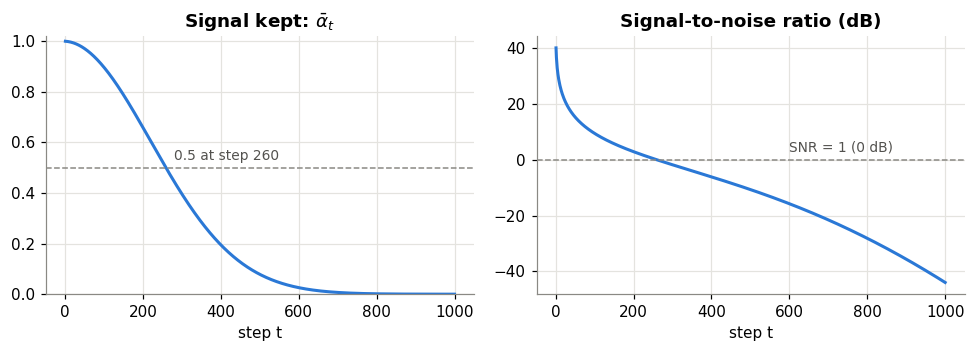

In [23]:
# Figure: the DDPM-style schedule (two measures with different scales -> two panels, no twin axis)
steps = np.arange(1, T_steps + 1)
snr_ddpm = alpha_bar_ddpm / (1 - alpha_bar_ddpm)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].plot(steps, alpha_bar_ddpm, color=BLUE, linewidth=2)
axes[0].axhline(0.5, color=GREY, linestyle="--", linewidth=1)
axes[0].text(first_below_half + 20, 0.53, f"0.5 at step {first_below_half}", fontsize=9, color="#52514e")
axes[0].set_title(r"Signal kept: $\bar{\alpha}_t$")
axes[0].set_xlabel("step t")
axes[0].set_ylim(0, 1.02)
axes[1].plot(steps, 10 * np.log10(snr_ddpm), color=BLUE, linewidth=2)
axes[1].axhline(0, color=GREY, linestyle="--", linewidth=1)
axes[1].text(600, 3, "SNR = 1 (0 dB)", fontsize=9, color="#52514e")
axes[1].set_title("Signal-to-noise ratio (dB)")
axes[1].set_xlabel("step t")
plt.tight_layout()
plt.show()

**What the figure shows:** the signal fades smoothly; the SNR falls from about +40 dB at the first step to about -44 dB at the last, so the final $x_T$ is practically pure noise and generation can start from random numbers.

### Try it yourself

A constant schedule $\beta_t = 0.2$ for 3 steps, $x_0 = 1.0$, $\epsilon = 1.0$. Find $\bar\alpha_3$, $x_3$ and the SNR at $t = 3$.

<details><summary>Answer</summary>

$\bar\alpha_3 = 0.8^3 = 0.512$. $x_3 = \sqrt{0.512} \times 1 + \sqrt{0.488} \times 1 = 0.715542 + 0.698570 = 1.414112$. SNR $= 0.512 / 0.488 = 1.0492$.

</details>

**Common mistake:** using $\beta_t$ (or $\alpha_t$) of the current step alone in the jump formula. The closed form needs the **cumulative product** $\bar\alpha_t$.

## 20. VAE and GAN: reparameterization, KL term and adversarial losses

**What it is:**
- A **VAE (variational autoencoder)** encodes an input into a mean $\mu$ and a spread $\sigma$, samples a code $z$, and decodes it. Its loss = reconstruction error + a **KL term** that keeps the codes close to a standard normal $N(0, 1)$.
- A **GAN (generative adversarial network)** has a **generator** $G$ that makes fakes and a **discriminator** $D$ that outputs the probability that its input is real.

**Everyday analogy:** the GAN is a forger and an art inspector improving against each other. The VAE is a librarian who files every book at a fuzzy location ($\mu \pm \sigma$) on a shared map, so nearby locations hold similar books.

**How it works:**
- reparameterization: $z = \mu + \sigma \cdot \epsilon$, with $\epsilon \sim N(0, 1)$ and $\sigma = e^{\frac{1}{2}\log\sigma^2}$
- $\text{KL}(N(\mu, \sigma^2) \,\Vert\, N(0, 1)) = \tfrac{1}{2}(\sigma^2 + \mu^2 - 1 - \ln\sigma^2)$ (summed over dimensions)
- discriminator loss $L_D = -[\ln D(x) + \ln(1 - D(G(z)))]$
- generator loss (non-saturating) $L_G = -\ln D(G(z))$; the original minimax generator instead minimises $\ln(1 - D(G(z)))$

### Problem

(a) VAE, one latent dimension: the encoder outputs $\mu = 0.5$ and $\log\sigma^2 = -1.0$; the sampled $\epsilon = 1.2$. Find $\sigma$, $z$ and the KL term.

(b) GAN: $D(x_{real}) = 0.9$ and $D(G(z)) = 0.2$. Find $L_D$, the non-saturating $L_G$, the minimax generator term, and compare the gradients that the two generator losses send back through the discriminator's logit. Also find both losses at the ideal balance $D = 0.5$.

### Solution by hand

**(a) VAE**
1. $\sigma = e^{-1.0/2} = e^{-0.5} = 0.606531$.
2. $z = 0.5 + 0.606531 \times 1.2 = 0.5 + 0.727837 = 1.227837 \approx 1.2278$. The randomness sits in $\epsilon$, so gradients can flow through $\mu$ and $\sigma$ (you cannot backpropagate through "draw a random number" directly).
3. $\sigma^2 = e^{-1} = 0.367879$, so $\text{KL} = \tfrac{1}{2}(0.367879 + 0.25 - 1 - (-1)) = \tfrac{1}{2} \times 0.617879 = 0.308940 \approx 0.3089$ nats.

**(b) GAN**
4. $L_D = -[\ln 0.9 + \ln(1 - 0.2)] = -[-0.105361 + (-0.223144)] = 0.328504 \approx 0.3285$. The discriminator is doing well.
5. Non-saturating $L_G = -\ln 0.2 = 1.609438 \approx 1.6094$. The minimax term is $\ln(1 - 0.2) = \ln 0.8 = -0.223144$.
6. **Gradients** through the logit $l$ of $D = \sigma(l)$ (here $\sigma(l) = 0.2$):
   - minimax: $\dfrac{d}{dl}\ln(1 - \sigma(l)) = -\sigma(l) = -0.2$
   - non-saturating: $\dfrac{d}{dl}[-\ln\sigma(l)] = -(1 - \sigma(l)) = -0.8$

   So the non-saturating loss gives the generator a 4 times stronger push when it is losing ($D(G(z))$ small), which is why it is used in practice.
7. **Balance $D = 0.5$:** $L_D = -2\ln 0.5 = 2\ln 2 = 1.3863$; $L_G = \ln 2 = 0.6931$.

In [24]:
mu, log_var, eps = 0.5, -1.0, 1.2
sigma = np.exp(0.5 * log_var)
z = mu + sigma * eps
kl_vae = 0.5 * (sigma ** 2 + mu ** 2 - 1 - log_var)
check("sigma", sigma, "0.606531")
check("sigma * eps", sigma * eps, "0.727837")
check("z", z, "1.2278")
check("sigma^2", sigma ** 2, "0.367879")
check("KL to N(0, 1)", kl_vae, "0.3089")

# cross-check the KL formula by numerical integration of p(z) * ln(p(z) / q(z))
zs = np.linspace(-10, 10, 200_001)
p = np.exp(-(zs - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))
q_ = np.exp(-zs ** 2 / 2) / np.sqrt(2 * np.pi)
kl_numeric = np.sum(p * np.log(p / q_)) * (zs[1] - zs[0])
check("KL by numerical integration", kl_numeric, "0.3089")

d_real, d_fake = 0.9, 0.2
check("ln 0.9", np.log(d_real), "-0.105361")
check("ln 0.8", np.log(1 - d_fake), "-0.223144")
check("discriminator loss", -(np.log(d_real) + np.log(1 - d_fake)), "0.3285")
check("generator loss (non-saturating)", -np.log(d_fake), "1.6094")
check("minimax generator term", np.log(1 - d_fake), "-0.223144")

# gradients w.r.t. the discriminator logit l, by finite differences
l = np.log(d_fake / (1 - d_fake))                      # logit with sigmoid(l) = 0.2
h = 1e-6
grad_minimax = (np.log(1 - sigmoid(l + h)) - np.log(1 - sigmoid(l - h))) / (2 * h)
grad_nonsat = (-np.log(sigmoid(l + h)) + np.log(sigmoid(l - h))) / (2 * h)
check("gradient, minimax", grad_minimax, "-0.2")
check("gradient, non-saturating", grad_nonsat, "-0.8")
check("L_D at balance (2 ln 2)", -2 * np.log(0.5), "1.3863")
check("L_G at balance (ln 2)", -np.log(0.5), "0.6931")

OK  sigma                                          code = 0.606531         hand = 0.606531
OK  sigma * eps                                    code = 0.727837         hand = 0.727837
OK  z                                              code = 1.22784          hand = 1.2278
OK  sigma^2                                        code = 0.367879         hand = 0.367879
OK  KL to N(0, 1)                                  code = 0.30894          hand = 0.3089
OK  KL by numerical integration                    code = 0.30894          hand = 0.3089
OK  ln 0.9                                         code = -0.105361        hand = -0.105361
OK  ln 0.8                                         code = -0.223144        hand = -0.223144
OK  discriminator loss                             code = 0.328504         hand = 0.3285
OK  generator loss (non-saturating)                code = 1.60944          hand = 1.6094
OK  minimax generator term                         code = -0.223144        hand = -0.223144
OK  gr

### Try it yourself

(1) A VAE latent with $\mu = 1.0$ and $\sigma = 0.5$: find the KL term. (2) A GAN with $D(x) = 0.6$ and $D(G(z)) = 0.7$: find $L_D$ and the non-saturating $L_G$. Who is winning?

<details><summary>Answer</summary>

(1) $\tfrac{1}{2}(0.25 + 1 - 1 - \ln 0.25) = \tfrac{1}{2}(0.25 + 1.386294) = 0.8181$. (2) $L_D = -(\ln 0.6 + \ln 0.3) = 0.510826 + 1.203973 = 1.7148$; $L_G = -\ln 0.7 = 0.3567$. The generator is winning: the discriminator calls the fake 70% real.

</details>

**Common mistake:** treating the encoder's second output as $\sigma$ when it is $\log\sigma^2$ (it is predicted in log form so it can be any real number). Then $\sigma = e^{\frac{1}{2}\log\sigma^2}$, not $e^{\log\sigma^2}$.

## 21. Context window budgeting

**What it is:** the **context window** is the maximum number of tokens a model can handle in one request: system prompt + examples + retrieved chunks + question **and** the answer it writes. Budgeting means deciding how much of it each part gets.

**Everyday analogy:** packing a carry-on bag with a fixed size. The essentials go in first (system prompt, question), you leave room for what you will buy on the trip (the answer), and then you fit as many extras (chunks, examples) as the space allows.

**How it works:** available = window − system prompt − question − reserved output; number of items = $\lfloor$ available ÷ tokens per item $\rfloor$ (round **down**).

### Problem

| Item | Tokens |
|---|---|
| context window (hypothetical model) | 8,192 |
| system prompt | 600 |
| user question | 150 |
| reserved for the answer | 1,024 |
| one retrieved chunk | 512 + 10 of formatting (separator and source tag) |
| one few-shot example | 350 |

Find: (a) the most chunks that fit; (b) the most few-shot examples with no chunks; (c) the most chunks if 3 few-shot examples are also included.

### Solution by hand

1. **Available:** $8{,}192 - 600 - 150 - 1{,}024 = 6{,}418$ tokens.
2. **Chunks:** each costs $512 + 10 = 522$; $6{,}418 / 522 = 12.30$, so **12 chunks** ($12 \times 522 = 6{,}264$ tokens, 154 left).
3. **Few-shot examples only:** $6{,}418 / 350 = 18.34$, so **18 examples** ($6{,}300$ tokens, 118 left).
4. **3 examples + chunks:** the examples use $3 \times 350 = 1{,}050$, leaving $6{,}418 - 1{,}050 = 5{,}368$; $5{,}368 / 522 = 10.28$, so **10 chunks** ($5{,}220$ tokens, 148 left).

Most APIs count the input **plus** the requested maximum output against the window, so always reserve the output. In a chat, the history also takes space and grows every turn. And more context is not free: it costs money (Section 1), slows the first token (Section 15) and can make answers worse when the key facts sit in the middle of a very long prompt.

In [25]:
window, system, question, reserve_out = 8192, 600, 150, 1024
chunk_cost, example_cost = 512 + 10, 350
available = window - system - question - reserve_out
check("available tokens", available, "6,418")
check("available / chunk", available / chunk_cost, "12.30")
check("max chunks", available // chunk_cost, "12")
check("tokens left after chunks", available - (available // chunk_cost) * chunk_cost, "154")
check("available / example", available / example_cost, "18.34")
check("max few-shot examples", available // example_cost, "18")
check("tokens left after examples", available - (available // example_cost) * example_cost, "118")
left = available - 3 * example_cost
check("left after 3 examples", left, "5,368")
check("left / chunk", left / chunk_cost, "10.28")
check("max chunks with 3 examples", left // chunk_cost, "10")
check("tokens left", left - (left // chunk_cost) * chunk_cost, "148")

OK  available tokens                               code = 6,418            hand = 6,418
OK  available / chunk                              code = 12.295           hand = 12.30
OK  max chunks                                     code = 12               hand = 12
OK  tokens left after chunks                       code = 154              hand = 154
OK  available / example                            code = 18.3371          hand = 18.34
OK  max few-shot examples                          code = 18               hand = 18
OK  tokens left after examples                     code = 118              hand = 118
OK  left after 3 examples                          code = 5,368            hand = 5,368
OK  left / chunk                                   code = 10.2835          hand = 10.28
OK  max chunks with 3 examples                     code = 10               hand = 10
OK  tokens left                                    code = 148              hand = 148


### Try it yourself

A 4,096-token window; system prompt 300; question 100; reserve 500 for the answer; each chunk is 300 tokens + 12 of formatting. How many chunks fit, and how many tokens are left over?

<details><summary>Answer</summary>

Available: $4{,}096 - 300 - 100 - 500 = 3{,}196$. Per chunk: 312. $3{,}196 / 312 = 10.24$, so 10 chunks ($3{,}120$ tokens), 76 left.

</details>

**Interview tip:** say the order out loud: fixed parts first (system, tools, question), then **reserve the output**, then fill what is left with retrieved context, best chunks first, and stop before the limit rather than truncating mid-chunk.

## Recap cheat sheet

| # | Topic | Formula / rule (approximate where marked) |
|---|---|---|
| 1 | Tokens | tokens ≈ words ÷ 0.75 (English, approximate) |
| 1 | API cost | $\text{in} \times p_{in}/10^6 + \text{out} \times p_{out}/10^6$; cached tokens at the cached price; batch = discount on all tokens |
| 2 | Temperature | $p_i = e^{z_i/T} / \sum_j e^{z_j/T}$; subtract the max logit first |
| 2 | Sampling | greedy = argmax; top-k = $k$ best; top-p = smallest set with total $\ge p$; min-p = keep $p_i \ge \text{min-p} \times p_{\max}$; renormalize |
| 3 | Perplexity | $\text{CE} = -\frac{1}{N}\sum \ln p_i$, $\text{PPL} = e^{\text{CE}} = 2^{\text{bits}}$, bits $= \text{CE}/\ln 2$; random guesser: $\ln V$ |
| 4 | Parameters | per layer $4d^2 + 2 d\,d_{ff}$ (+ biases, norms); total $\approx 12Ld^2 + Vd$ |
| 5 | Attention | $n^2$ scores per head; $QK^\top$ + $AV$ = $4n^2d$ FLOPs; projections $8nd^2$ |
| 6 | Positions | $\sin/\cos(pos/10000^{2i/d})$; RoPE: rotate pairs by $m\theta$, score depends on $m - n$ |
| 7 | Training compute | $C \approx 6ND$; time $= C / (\text{peak} \times \text{MFU})$; 1 PF/s-day $= 8.64 \times 10^{19}$ FLOPs |
| 7 | Chinchilla | $D \approx 20N$ (approximate); $N = \sqrt{C/120}$; inference $\approx 2N$ FLOPs per token |
| 8 | Weights | params × bytes (4 / 2 / 1 / 0.5) |
| 8 | Training memory | ≈ 16 bytes per parameter with Adam (mixed precision) + activations |
| 9 | KV cache | $2 \cdot L \cdot n_{kv} \cdot d_{head} \cdot \text{seq} \cdot \text{batch} \cdot \text{bytes}$; max batch $= \lfloor \text{free} / \text{per seq} \rfloor$ |
| 10 | Quantization | symmetric $s = \max\lvert x\rvert/127$; asymmetric $s = (x_{\max} - x_{\min})/255$, $z = \text{round}(-x_{\min}/s)$; error $\le s/2$ |
| 11 | Pruning | sparsity = zeros ÷ total; sparse storage = non-zeros × (value + index bytes); 2:4 = 2 of every 4 kept |
| 12 | Distillation | $\alpha\,\text{CE}(y, p_s) + (1 - \alpha)\,T^2\,\text{KL}(p_t^T \,\Vert\, p_s^T)$ |
| 13 | LoRA / prompts | LoRA $r(d + k)$ per matrix; prompt tuning $n_{virt} \cdot d$; prefix $n_{virt} \cdot 2 L d$ |
| 14 | MoE | total = shared + all experts; active = shared + top-$k$ experts; FLOPs ≈ 2 × active |
| 15 | Latency | $\text{TTFT} + (N - 1)\,\text{TPOT}$; batch-1 tokens/s $\le$ bandwidth ÷ weight bytes |
| 15 | Speculative decoding | tokens per pass $= (1 - a^{k+1})/(1 - a)$; speed-up $= \text{that} / (kc + 1)$ |
| 16 | Chunking | stride $= C - O$; chunks $= 1 + \lceil (N - C)/S \rceil$ |
| 16 | Vector storage | vectors × dims × bytes (float32 = 4) |
| 16 | Retrieval metrics | P@k = hits/k; R@k = hits/relevant; MRR = mean of 1/first-hit rank; nDCG = DCG/IDCG with $\log_2(i+1)$ |
| 17 | EM / F1 | normalise; EM = equal or not; $F_1 = 2PR/(P + R)$ on shared tokens |
| 17 | Elo | $E_A = 1/(1 + 10^{(R_B - R_A)/400})$; $R_A' = R_A + K(S_A - E_A)$ |
| 18 | Reward model | $P = \sigma(r_c - r_r)$, loss $= -\ln\sigma(r_c - r_r)$; reward $- \beta \cdot \text{KL}$ |
| 18 | PPO / DPO | $\min(\rho A, \text{clip}(\rho, 1\pm\epsilon) A)$; DPO $= -\ln\sigma(\beta \cdot \text{margin of log-ratios})$ |
| 19 | Diffusion | $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1 - \bar\alpha_t}\,\epsilon$; $\bar\alpha_t = \prod(1 - \beta_s)$; SNR $= \bar\alpha/(1 - \bar\alpha)$ |
| 20 | VAE | $z = \mu + \sigma\epsilon$; KL $= \frac{1}{2}(\sigma^2 + \mu^2 - 1 - \ln\sigma^2)$ |
| 20 | GAN | $L_D = -[\ln D(x) + \ln(1 - D(G(z)))]$; $L_G = -\ln D(G(z))$ |
| 21 | Context budget | items $= \lfloor (\text{window} - \text{fixed} - \text{reserved output}) / \text{item size} \rfloor$ |

## Related notebooks in this repo

- [How LLMs work (start here)](00_start_here_how_llms_work.ipynb): tokens, next-token prediction, sampling in plain words
- [Transformer and LLM mechanics: math and code](30_transformer_and_llm_mechanics_math_and_code.ipynb): attention, RoPE, parameter counts and the KV cache in code
- [Tokens, cost, batching and caching for LLM APIs](27_tokens_cost_batch_and_caching_llm_apis.ipynb): Sections 1 and 21 in depth
- [Caching in LLM systems: KV cache, prompt, semantic, CAG](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb): Sections 9 and 15
- [How LLMs differ from each other](24_how_llms_differ_from_each_other.ipynb): GQA, MoE, context length and more design choices
- [LLM inference optimization](13_inference_optimization.ipynb): quantization, batching, speculative decoding
- [LLM architecture innovations](14_llm_architecture_innovations.ipynb) and [Alignment techniques](12_alignment_techniques.ipynb): MoE, RLHF, DPO
- [Fine-tuning](03_fine_tuning/01_fine_tuning.ipynb) and [Fine-tuning hands-on on CPU](21_fine_tuning_hands_on_cpu.ipynb): LoRA and QLoRA in practice
- [LLM evaluation](08_evaluation/01_llm_evaluation.ipynb) and [LLM evaluation hands-on](22_llm_evaluation_hands_on.ipynb): Section 17 in practice
- [RAG fundamentals](02_rag/01_rag_fundamentals.ipynb), [Advanced RAG](02_rag/02_advanced_rag.ipynb) and [Advanced retrieval and reranking](02_rag/04_advanced_retrieval_and_reranking.ipynb): Section 16 in practice
- [Deep learning numericals](../05_Deep_Learning/00b_dl_numericals_solved_by_hand.ipynb) and [NLP numericals](../07_NLP/00b_nlp_numericals_solved_by_hand.ipynb): the companion problem sets (ROUGE and BLEU are there)
- [Generative models](../05_Deep_Learning/06_generative_models.ipynb), [Advanced PEFT](../05_Deep_Learning/12_advanced_peft.ipynb), [Quantization and compression](../05_Deep_Learning/13_quantization_and_compression_advanced.ipynb) and [Distributed training](../05_Deep_Learning/11_distributed_training.ipynb)
- [Information theory](../14_Mathematics/05_information_theory.ipynb): entropy, cross-entropy and KL divergence from first principles

## Additional Learning Resources

Papers (all free on arXiv):
- Vaswani et al., *Attention Is All You Need* (2017), arXiv:1706.03762: the transformer, sinusoidal positions
- Kaplan et al., *Scaling Laws for Neural Language Models* (2020), arXiv:2001.08361, and Hoffmann et al., *Training Compute-Optimal Large Language Models* ("Chinchilla", 2022), arXiv:2203.15556
- Holtzman et al., *The Curious Case of Neural Text Degeneration* (top-p sampling, 2019), arXiv:1904.09751
- Su et al., *RoFormer: Enhanced Transformer with Rotary Position Embedding* (2021), arXiv:2104.09864
- Shazeer, *Fast Transformer Decoding: One Write-Head is All You Need* (MQA, 2019), arXiv:1911.02150, and Ainslie et al., *GQA* (2023), arXiv:2305.13245
- Rajbhandari et al., *ZeRO: Memory Optimizations Toward Training Trillion Parameter Models* (2019), arXiv:1910.02054
- Dao et al., *FlashAttention* (2022), arXiv:2205.14135; Kwon et al., *PagedAttention / vLLM* (2023), arXiv:2309.06180
- Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models* (2021), arXiv:2106.09685; Dettmers et al., *QLoRA* (2023), arXiv:2305.14314; Lester et al., *The Power of Scale for Parameter-Efficient Prompt Tuning* (2021), arXiv:2104.08691
- Hinton, Vinyals and Dean, *Distilling the Knowledge in a Neural Network* (2015), arXiv:1503.02531
- Leviathan, Kalman and Matias, *Fast Inference from Transformers via Speculative Decoding* (2023), arXiv:2211.17192
- Schulman et al., *Proximal Policy Optimization Algorithms* (2017), arXiv:1707.06347; Ouyang et al., *Training language models to follow instructions with human feedback* (2022), arXiv:2203.02155; Rafailov et al., *Direct Preference Optimization* (2023), arXiv:2305.18290
- Ho, Jain and Abbeel, *Denoising Diffusion Probabilistic Models* (2020), arXiv:2006.11239; Kingma and Welling, *Auto-Encoding Variational Bayes* (2013), arXiv:1312.6114; Goodfellow et al., *Generative Adversarial Networks* (2014), arXiv:1406.2661
- Rajpurkar et al., *SQuAD* (2016), arXiv:1606.05250 (exact match and F1 for QA)

Courses (free to audit or free):
- Hugging Face courses, including the LLM course: https://huggingface.co/learn
- DeepLearning.AI and AWS, *Generative AI with Large Language Models* (Coursera): https://www.coursera.org/learn/generative-ai-with-llms
- DeepLearning.AI short courses on generative AI: https://www.deeplearning.ai/short-courses/